# Which contract should a household with no battery sign?

One question asked three times, on the same Fluvius households the horizon study uses —
`PER_GROUP` from each of the 8 groups, full year, 15-minute intervals, no battery anywhere.
`PER_GROUP` is set in section 0 and defaults to 5, i.e. 40 households.

With no battery there is no dispatch decision: the household imports exactly what it did not
generate in the interval it did not generate it, and exports the rest. The annual bill is a pure
function of the price list, which separates two differently-priced problems — being on the wrong
contract, worth up to 20 % of the bill, and needing a battery, worth ~30 kWh of hardware.

### The chapters

| | who | export credited at | asks |
|---|---|---|---|
| **1** | the 20 households with no PV | — nothing to export | which plain supply list, billed under `si_dobava` |
| **2** | the 20 households with PV | the list's own `tip_odkupa` | which *samooskrba* list, billed under `si_samooskrba` |
| **3** | the same 20 with PV | zero | the same lists for a household that may not sell |
| **4** | best 3 and worst 3 contracts, PV only | both | what the right to sell the surplus is actually worth |

Chapters 2 and 3 are the same computation with one term changed: the import side, the fixed
charges and the excess-power charge are held identical, so everything that moves is the buyback.

### A contract is a price list *and* a meter

A Slovenian *tarifni* list usually publishes three supplier rates: `VT` and `MT` for a two-tariff
meter, and a single `ET` rate for a one-tariff one. Every row is therefore a price option — a
list plus, where the supplier publishes both, which variant is billed.

| in the tables | what it means |
|---|---|
| `… [2T]` | two-tariff meter, billed `VT` in the high window and `MT` otherwise |
| `… [1T]` | single-tariff meter, billed the flat `ET` rate around the clock |
| no suffix | the list offers no such choice — a 4-block or spot-linked list, or a *tarifni* list publishing only one |

`GEN-I Samo Redni` is 1T only; `Petrol Samooskrba` publishes both. On the no-PV side most lists
appear twice, which is why 15 price lists become 25 options.

### What "no PV" and "with PV" mean in this data

The Fluvius columns are meter registers, not gross load and gross production, and they are very
nearly mutually exclusive — both non-zero in 9.7 % of the PV-household intervals. The roof's
self-consumption has already been netted away before the data starts, so what every chapter
prices is the residual: the import that survived the roof and the surplus it could not absorb.
Chapter 3 removes the value of the surplus only, never the larger saving the roof makes by
displacing retail import.

In [1]:
### Imports
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Patch

import importlib
import Horizon_Comparison as hc
hc = importlib.reload(hc)
from Pricing_Functions import PAKETI

RESULTS_DIR = hc.RESULTS_DIR.parent          # Results/, where the three caches live


def cache_path(name, per_group):
    """Cache file for one chapter at one sample size.

    The sample size is in the FILENAME, not just in a column: two settings then
    coexist instead of overwriting each other, so switching PER_GROUP back and
    forth costs nothing after the first run of each. The column is still checked
    on read -- the name says what a file should be, the column says what it is.
    """
    return RESULTS_DIR / f"{name}_pg{int(per_group)}.csv"
print(f"Horizon_Comparison loaded: {len(hc.consumer_price_lists())} plain supply lists, "
      f"{len(hc.prosumer_price_lists())} samooskrba lists.")

Horizon_Comparison loaded: 25 plain supply lists, 6 samooskrba lists.


## 0. What the bill is made of, and the one thing a contract cannot change

The study parameters live in `Horizon_Comparison.py`, the same module the horizon study reads.

`PER_GROUP` sets how many households are drawn from each of the 8 Fluvius groups, so the sample
stays a balanced panel at any setting. Each comparison records its own `Per_Group` on every row,
so a cache written at one setting is recomputed rather than misread at another.

The bill has three parts, and only the first is competitive:

| part | what it is | can a contract change it? |
|---|---|---|
| **energy** | supplier price + `omrežnina` energy rate per block + levies, ×1.22 VAT, minus the buyback credit | yes — this is the whole spread between suppliers |
| **fixed** | `omrežnina` power rate × agreed power + OVE/SPTE + the supplier's monthly fee | only through the monthly fee and the agreed power |
| **excess power** | `omrežnina` power rate × (monthly peak − agreed power) × 1.05 | no — identical on every list |

The last two move with the agreed billing power, modelled as a household that agrees exactly the
per-block peak the previous month realized, with no floor and no ceiling and only the Akt's
monotonicity rule applied. The leading month is bootstrapped from the last complete month of the
same dataset.

The excess-power charge is the same number on every list, so it is never a reason to prefer a
contract — it is the line a battery moves. Choosing your own agreed power is what makes it
payable: a household that leaves its assigned figure alone is exempt.

In [2]:
### Recompute switches -----------------------------------------------------
# Every chapter reads a cache and only re-solves when its switch is True. They
# live here rather than in the chapter cells so the cost of running this
# notebook is visible in one place, before anything executes.
# A cache is dropped automatically anyway when it was written under a different
# agreed-power rule or a different PER_GROUP, so False never silently serves a
# stale bill -- it only avoids recomputing a still-valid one.
RUN_NO_PV     = True   # chapter 1 -- every no-PV household on every plain-supply list
RUN_PV        = False  # chapter 2 -- every PV household on every samooskrba list
RUN_PV_NOSALE = False  # chapter 3 -- the same PV households with the surplus worth nothing
RUN_CATALOGUE = False  # chapter 5 -- both catalogues on both household sets

PER_GROUP = 5        # households drawn from EACH Fluvius group; 1-2 for a fast pass

UNITS = hc.study_units(per_group=PER_GROUP)
NO_PV_UNITS = hc.study_units(hc.NO_PV_GROUPS, PER_GROUP)
PV_UNITS = hc.study_units(hc.PV_GROUPS, PER_GROUP)

print(f"households         : {PER_GROUP} per group = {len(UNITS)} units, no battery")
print(f"   no PV           : {len(NO_PV_UNITS)} units  "
      f"({', '.join(hc.NO_PV_GROUPS)})")
print(f"   with PV         : {len(PV_UNITS)} units  "
      f"({', '.join(hc.PV_GROUPS)})")
print(f"pricing regime     : {hc.PRICING_REFERENCE_YEAR}")
print(f"   no PV           : scheme {hc.CONSUMER_SCHEME} -- a plain supply contract")
print(f"   with PV         : scheme {hc.PROSUMER_SCHEME} -- netting INSIDE the 15-min "
      f"interval, then the surplus is credited")
print(f"agreed power       : {hc.AGREED_POWER_TAG}, leading month "
      f"{hc.AGREED_POWER_BOOTSTRAP!r}; identical in every chapter")
print(f"peak reset         : every {hc.PEAK_RESET_MONTHS} month(s), tag "
      f"{hc.PEAK_RESET_TAG!r} -- the excess-power charge is billed monthly")

# One row per price option: a list plus, where the supplier publishes both,
# which metering variant it is billed on. `Structure` names the actual rate.
consumer_options = hc.consumer_price_lists()
prosumer_options = hc.prosumer_price_lists()
n_consumer_lists = len({hc.option_base_id(o) for o in consumer_options})
n_prosumer_lists = len({hc.option_base_id(o) for o in prosumer_options})

print(f"\nplain supply options (chapter 1): {len(consumer_options)} "
      f"from {n_consumer_lists} price lists")
for o in consumer_options:
    p = PAKETI[hc.option_base_id(o)]
    print(f"   {hc.option_label(o):26s} {p.dobavitelj:18s} "
          f"{hc.tariff_structure_label(o):30s} fee {p.nadomestilo(True):.2f} EUR/mo")

print(f"\nsamooskrba options (chapters 2-4): {len(prosumer_options)} "
      f"from {n_prosumer_lists} price lists")
for o in prosumer_options:
    p = PAKETI[hc.option_base_id(o)]
    print(f"   {hc.option_label(o):26s} {p.dobavitelj:18s} "
          f"{hc.tariff_structure_label(o):30s} buyback: {hc.buyback_rate_label(o)}")

split = sorted({hc.option_base_id(o) for o in consumer_options + prosumer_options
                if hc.option_variant(o) != hc.VARIANT_NA})
print(f"\n{len(split)} lists publish BOTH a VT/MT and an ET rate and so appear twice: "
      f"{', '.join(split)}")
print("NET metering is left out on purpose: it is closed to new consents and settles "
      "once a year,\nso it is neither a list a household can choose into nor a bill a "
      "per-interval evaluator can write.")

households         : 5 per group = 40 units, no battery
   no PV           : 20 units  (Fluvius, Fluvius_EV, Fluvius_HP, Fluvius_HP_EV)
   with PV         : 20 units  (Fluvius_PV, Fluvius_PV_EV, Fluvius_PV_HP, Fluvius_PV_HP_EV)
pricing regime     : 2026
   no PV           : scheme si_dobava -- a plain supply contract
   with PV         : scheme si_samooskrba -- netting INSIDE the 15-min interval, then the surplus is credited
agreed power       : prev1m_top5_cyclic_unbounded_dispatch, leading month 'cyclic'; identical in every chapter
peak reset         : every 1 month(s), tag '1m' -- the excess-power charge is billed monthly

plain supply options (chapter 1): 25 from 15 price lists
   BISOL_DINAMICNI            BISOL Energija     dynamic: SIPX + 0.01300        fee 1.63 EUR/mo
   BISOL_DINAMICNI_PLUS       BISOL Energija     dynamic: SIPX + 0.01300        fee 3.26 EUR/mo
   BISOL_FIKSNI [2T]          BISOL Energija     2T: VT 0.12700 / MT 0.10700    fee 1.63 EUR/mo
   BISOL_FIKSNI [1T] 

In [3]:
### Shared chart styling
import importlib
import Plotting_Functions as pf   # one module decides style, size and export

# Reloaded like the other repo modules in the imports cell: `import` returns
# whatever the kernel cached the first time, so editing Plotting_Functions and
# re-running this cell would otherwise keep the old module -- which shows up as
# a TypeError about an argument that does exist in the file.
pf = importlib.reload(pf)

# titles=False: an IEEE figure carries no title of its own -- the caption below
# it, set in the article, is the title. The text is not lost, it goes into each
# export's SOURCE.md as the caption to use. Flip to True to read the figures
# with their titles in the notebook.
pf.use(subdir="no_battery", titles=False)
from Plotting_Functions import INK, INK_2, MUTED, SURFACE, SERIES, EUR, PCT, finish

# ---------------------------------------------------------------------------
# What the colour channel means, and it means only this:
#
#   hue      one categorical question per chapter -- the export regime in
#            chapters 2-4 (credited blue, no sale orange), the catalogue in
#            chapter 5 (plain supply purple, samooskrba green). The two pairs
#            are never drawn in the same axes.
#   ramp     magnitude: one hue, light -> dark, identity coming off the
#            labelled axis. Neutral where the rows span both catalogues.
#   shade    household type, a neutral ramp by annual demand.
#
# Nothing here is ever the rank of a bar: a filter that drops a list must not
# repaint the survivors.
#
# The palette itself is shared (pf.SERIES); what a colour MEANS is this study's
# semantics and stays here. The catalogue pair is outside SERIES because it is
# a second categorical question that never shares an axes with the first.
REGIME_COLOR = {"credited": SERIES[0], "nosale": SERIES[1]}
REGIME_LABEL = {"credited": "presežke odkupi dobavitelj",
                "nosale":   "presežkov ni mogoče prodati"}
CATALOGUE_ORDER = ("dobava", "samooskrba")
CATALOGUE_COLOR = {"dobava": "#a03fa0", "samooskrba": "#2f9e44"}
CATALOGUE_SHORT = {"dobava": "dobava", "samooskrba": "samooskrba"}
CATALOGUE_LABEL = {
    "dobava": "cenik za dobavo brez samooskrbe (odjemalec s PV ga ne sme podpisati)",
    "samooskrba": "samooskrbni cenik, presežki ovrednoteni z 0 EUR",
}


def rows_ratio(n, per_row=0.34, floor=4.4):
    """Height/width for a horizontal bar chart with `n` rows.

    `pf.figsize` takes an aspect rather than a height, and these panels have as
    many rows as the chapter has price lists -- 6 in one, 31 in another. The row
    PITCH is what has to stay constant across them, not the figure height, so
    the aspect is derived from the row count at the shared width.
    """
    return max(floor, per_row * n) / pf.PRESETS[pf.PRESET]


def key_below(ax, handles, labels=None, ncol=4, gap_in=0.52, **kw):
    """Legend under the x-axis label, a fixed distance below the axes.

    A horizontal bar chart with a full-width bar in every row has no free
    corner, so an inside legend lands on top of data -- `pf.key_legend` does the
    placing. The gap is given in INCHES because a fraction of the axes height is
    the wrong unit once the same chapter draws a 6-row panel and a 31-row one:
    the default -0.16 is a finger's width under the short figure and a hand's
    width under the tall one.
    """
    if labels is not None:
        kw["labels"] = labels
    kw.setdefault("fontsize", 8)
    y = -gap_in / max(1.0, 0.78 * ax.figure.get_figheight())
    return pf.key_legend(ax, handles, ncol=ncol, bbox_to_anchor=(0.5, y), **kw)


def group_label(dataset):
    """Household type as a chart label: the dataset prefix carries no meaning."""
    return "osnovni" if dataset == "Fluvius" else str(dataset).replace("Fluvius_", "")


def group_shades(groups, base=INK_2):
    """One neutral shade per household type, light -> dark by position.

    Household type is ORDERED (plain -> EV -> HP -> HP+EV, by annual demand), so
    it gets a single hue ramped rather than a categorical palette -- the
    categorical channel stays reserved for the export regime.
    """
    return [pf.mix(base, "#ffffff", t) for t in np.linspace(0.72, 0.05, len(groups))]


def short_list_name(option_id, variant=True):
    """Chart-axis label for one price OPTION.

    The metering variant is part of the identity, not a footnote: two rows that
    read "GEN-I Redni" and differ by 8 EUR/a would be unreadable, so a list that
    publishes both a VT/MT and an ET rate always carries its [2T]/[1T] tag.
    """
    base = hc.option_base_id(option_id)
    name = (base.replace("GENI_SAMO_", "GEN-I Samo ").replace("GENI_", "GEN-I ")
            .replace("BISOL_SAMO_", "BISOL Samo ").replace("BISOL_", "BISOL ")
            .replace("PETROL_", "Petrol ").replace("ELEN_", "El. energija ")
            .replace("_", " ").title()
            .replace("Gen-I", "GEN-I").replace("Bisol", "BISOL"))
    tag = hc.option_variant(option_id)
    return f"{name} [{tag}]" if variant and tag != hc.VARIANT_NA else name


def bar_labels(ax, ypos, values, fmt="{:.0f}", pad=None, color=INK_2, fontsize=8):
    """Direct value labels at the end of horizontal bars.

    Every panel below is directly labelled rather than read off the grid: the
    numbers are euros a household would pay, and a 4 EUR/a difference between
    two lists is invisible at bar length but decisive at the till.
    """
    span = float(np.max(values)) if len(values) else 1.0
    pad = span * 0.012 if pad is None else pad
    for y, v in zip(ypos, values):
        ax.text(v + pad, y, fmt.format(v), va="center", ha="left",
                fontsize=fontsize, color=color)


def ranked_bill_panel(ax, summary, hue, title, xlabel, best_marker=True):
    """One ranked horizontal bar chart of the mean annual bill per price list.

    Identity is on the y axis, magnitude in the bar, so this is a single-hue
    ramp: darkest for the cheapest list. The cheapest row is called out in
    words as well as in shade, so the ranking never rests on colour alone.
    """
    n = len(summary)
    shades = [pf.mix(hue, "#ffffff", t) for t in np.linspace(0.0, 0.62, n)]
    ypos = np.arange(n)[::-1]
    ax.barh(ypos, summary["Cost_EUR"], height=0.68, color=shades)
    ax.set_yticks(ypos, [short_list_name(p) for p in summary.index], fontsize=8.5)
    bar_labels(ax, ypos, summary["Cost_EUR"].to_numpy())
    if best_marker:
        ax.text(summary["Cost_EUR"].iloc[0] * 0.5, ypos[0], "najcenejši",
                va="center", ha="center", fontsize=8, color="#ffffff",
                fontweight="semibold")
    ax.set_xlim(0, summary["Cost_EUR"].max() * 1.14)
    finish(ax, title=title, xlabel=xlabel)
    ax.grid(axis="x")
    ax.spines["left"].set_visible(False)
    return ypos


def overpay_heatmap(ax, table, hue, title, cbar_label="% nad najboljšim", fig=None,
                    cell_fontsize=7.5, label_fontsize=8, fmt="{:.1f}"):
    """Per-household-type overpayment against that group's own cheapest list.

    A magnitude with a meaningful floor at 0 %, so: one hue, light -> dark, and
    every cell carries its number because a heatmap alone is not readable to a
    colour-blind reader. The two font sizes are arguments because the same panel
    is drawn at 6 rows and at 32: the defaults are the 6-row setting.
    """
    values = table.to_numpy()
    im = ax.imshow(values, cmap=pf.ramp(hue, "overpay"), aspect="auto",
                   vmin=0, vmax=float(np.nanmax(values)))
    ax.set_xticks(range(table.shape[1]),
                  [group_label(c) for c in table.columns],
                  rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(table.shape[0]),
                  [short_list_name(p) for p in table.index], fontsize=label_fontsize)
    ax.grid(False)
    cut = float(np.nanmax(values)) * 0.62
    for r in range(values.shape[0]):
        for c in range(values.shape[1]):
            ax.text(c, r, fmt.format(values[r, c]), ha="center", va="center",
                    fontsize=cell_fontsize,
                    color="#ffffff" if values[r, c] > cut else INK)
    finish(ax, title=title)
    if fig is not None:
        fig.colorbar(im, ax=ax, fraction=0.045, pad=0.02, label=cbar_label)
    return im


print("Style ready: hue = one categorical question per chapter (export regime in 2-4, "
      "catalogue in 5),\nboth pairs validated all-pairs; ramps = magnitude, "
      "shades = household type.")

Style ready: hue = one categorical question per chapter (export regime in 2-4, catalogue in 5),
both pairs validated all-pairs; ramps = magnitude, shades = household type.


## 1. Which price list should a household with **no PV** sign?

Three of the four lists the horizon study runs carry `zahteva_pv=True` and are sold only with a
self-consumption device. A household with no PV chooses from the plain supply lists instead,
billed under `si_dobava`.

With no PV and no battery there is no dispatch decision, so this is a pure price-list question
and the answer is the cheapest annual bill.

`Delta` is measured against the cheapest list for that same household, then averaged, so a list
is not flattered by a household mix that suits it. `Cheapest for` counts the households it wins.

In [4]:
### Every no-PV household on every list it could actually sign, zero battery
# The per-interval unit rate depends only on the calendar and the market price,
# so one pass per list prices all 20 households.
NO_PV_CACHE = cache_path("no_pv_tariff_comparison", PER_GROUP)

# Keyed on the agreed-power rule as well: a cache written against a different
# dogovorjena moc is a different bill, not an older one.
cached = pd.read_csv(NO_PV_CACHE) if NO_PV_CACHE.exists() else None
if cached is not None and hc.agreed_power_tag(cached) != {hc.AGREED_POWER_TAG}:
    print(f"cache written under agreed power {sorted(hc.agreed_power_tag(cached))} != "
          f"{hc.AGREED_POWER_TAG!r}; recomputing")
    cached = None
# A frame built on a different PER_GROUP is a different sample.
if cached is not None and hc.sample_tag(cached) != {PER_GROUP}:
    print(f"cache written for per_group {sorted(hc.sample_tag(cached), key=str)} != "
          f"{PER_GROUP}; recomputing")
    cached = None

if RUN_NO_PV or cached is None:
    df_no_pv = hc.no_pv_tariff_comparison(per_group=PER_GROUP, verbose=True)
    df_no_pv.to_csv(NO_PV_CACHE, index=False)
else:
    df_no_pv = cached

no_pv_summary = hc.summarize_no_pv_tariffs(df_no_pv)
best_list = no_pv_summary.index[0]

print(f"{df_no_pv['Household'].nunique() * df_no_pv['Dataset'].nunique()} households "
      f"({', '.join(hc.NO_PV_GROUPS)}), {len(no_pv_summary)} price options from "
      f"{df_no_pv['Paket_ID'].nunique()} lists, no battery, full year under si_dobava\n")
print(f"cheapest on average : {best_list}  "
      f"({no_pv_summary.loc[best_list, 'Cost_EUR']:.0f} EUR/a, "
      f"cheapest for {no_pv_summary.loc[best_list, 'Cheapest_For']} of "
      f"{int(no_pv_summary.loc[best_list, 'Households'])} households)")
print(f"most expensive      : {no_pv_summary.index[-1]}  "
      f"({no_pv_summary['Cost_EUR'].iloc[-1]:.0f} EUR/a, "
      f"{no_pv_summary['Delta_pct'].iloc[-1]:.1f} % above the best available)")
print(f"spread, best to worst: "
      f"{no_pv_summary['Cost_EUR'].iloc[-1] - no_pv_summary['Cost_EUR'].iloc[0]:.0f} EUR/a")

no_pv_summary.rename(columns={
    "Households": "Households",
    "Cost_EUR": "Bill [EUR/a]",
    "Delta_EUR": "vs best [EUR/a]",
    "Delta_pct": "vs best [%]",
    "Worst_Delta_pct": "worst household [%]",
    "Energy_EUR": "energy [EUR/a]",
    "Fixed_EUR": "fixed [EUR/a]",
    "Excess_Power_EUR": "excess power [EUR/a]",
    "Cheapest_For": "cheapest for",
}).round(2)

  Fluvius 1: 2255 kWh
  Fluvius 2: 2513 kWh
  Fluvius 3: 2864 kWh
  Fluvius 4: 2765 kWh
  Fluvius 5: 734 kWh
  Fluvius_EV 1: 3194 kWh
  Fluvius_EV 2: 10023 kWh
  Fluvius_EV 3: 3824 kWh
  Fluvius_EV 4: 6395 kWh
  Fluvius_EV 5: 3923 kWh
  Fluvius_HP 1: 10335 kWh
  Fluvius_HP 2: 9230 kWh
  Fluvius_HP 3: 6827 kWh
  Fluvius_HP 4: 9198 kWh
  Fluvius_HP 5: 9969 kWh
  Fluvius_HP_EV 1: 10145 kWh
  Fluvius_HP_EV 2: 16413 kWh
  Fluvius_HP_EV 3: 9537 kWh
  Fluvius_HP_EV 4: 5761 kWh
  Fluvius_HP_EV 5: 4606 kWh
20 households (Fluvius, Fluvius_EV, Fluvius_HP, Fluvius_HP_EV), 25 price options from 15 lists, no battery, full year under si_dobava

cheapest on average : BISOL_FIKSNI99@1T  (1203 EUR/a, cheapest for 13 of 20 households)
most expensive      : PETROL_REDNI@1T  (1359 EUR/a, 13.5 % above the best available)
spread, best to worst: 156 EUR/a


,Supplier,Structure,Variant,Households,Bill [EUR/a],vs best [EUR/a],vs best [%],worst household [%],energy [EUR/a],fixed [EUR/a],excess power [EUR/a],cheapest for
Option,,,,,,,,,,,,
BISOL_FIKSNI99@1T,BISOL Energija,1T: ET 0.09900,1T,20,1203.22,7.36,0.66,5.01,955.93,224.70,22.59,13
BISOL_FIKSNI99@2T,BISOL Energija,2T: VT 0.10900 / MT 0.09400,2T,20,1213.89,18.03,1.69,4.07,966.60,224.70,22.59,0
GENI_DINAMICNI,GEN-I,dynamic: SIPX + 0.01199,-,20,1235.87,40.02,3.87,8.96,983.61,229.68,22.59,5
ELEN_DINAMICNA,Elektro energija,dynamic: SIPX + 0.01199,-,20,1238.65,42.80,4.22,9.84,983.61,232.46,22.59,0
BISOL_FIKSNI_VEZAVA@2T,BISOL Energija,2T: VT 0.11600 / MT 0.09600,2T,20,1246.63,50.78,4.39,6.83,999.35,224.70,22.59,0
BISOL_FIKSNI_VEZAVA@1T,BISOL Energija,1T: ET 0.10500,1T,20,1250.98,55.12,4.53,9.62,1003.70,224.70,22.59,0
GENI_REDNI@2T,GEN-I,2T: VT 0.11990 / MT 0.09790,2T,20,1259.12,63.26,4.99,6.76,1021.21,215.33,22.59,1
BISOL_DINAMICNI,BISOL Energija,dynamic: SIPX + 0.01300,-,20,1260.29,64.44,5.71,11.66,1013.01,224.70,22.59,0
GENI_REDNI@1T,GEN-I,1T: ET 0.10890,1T,20,1272.66,76.80,5.85,11.75,1034.75,215.33,22.59,0


findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


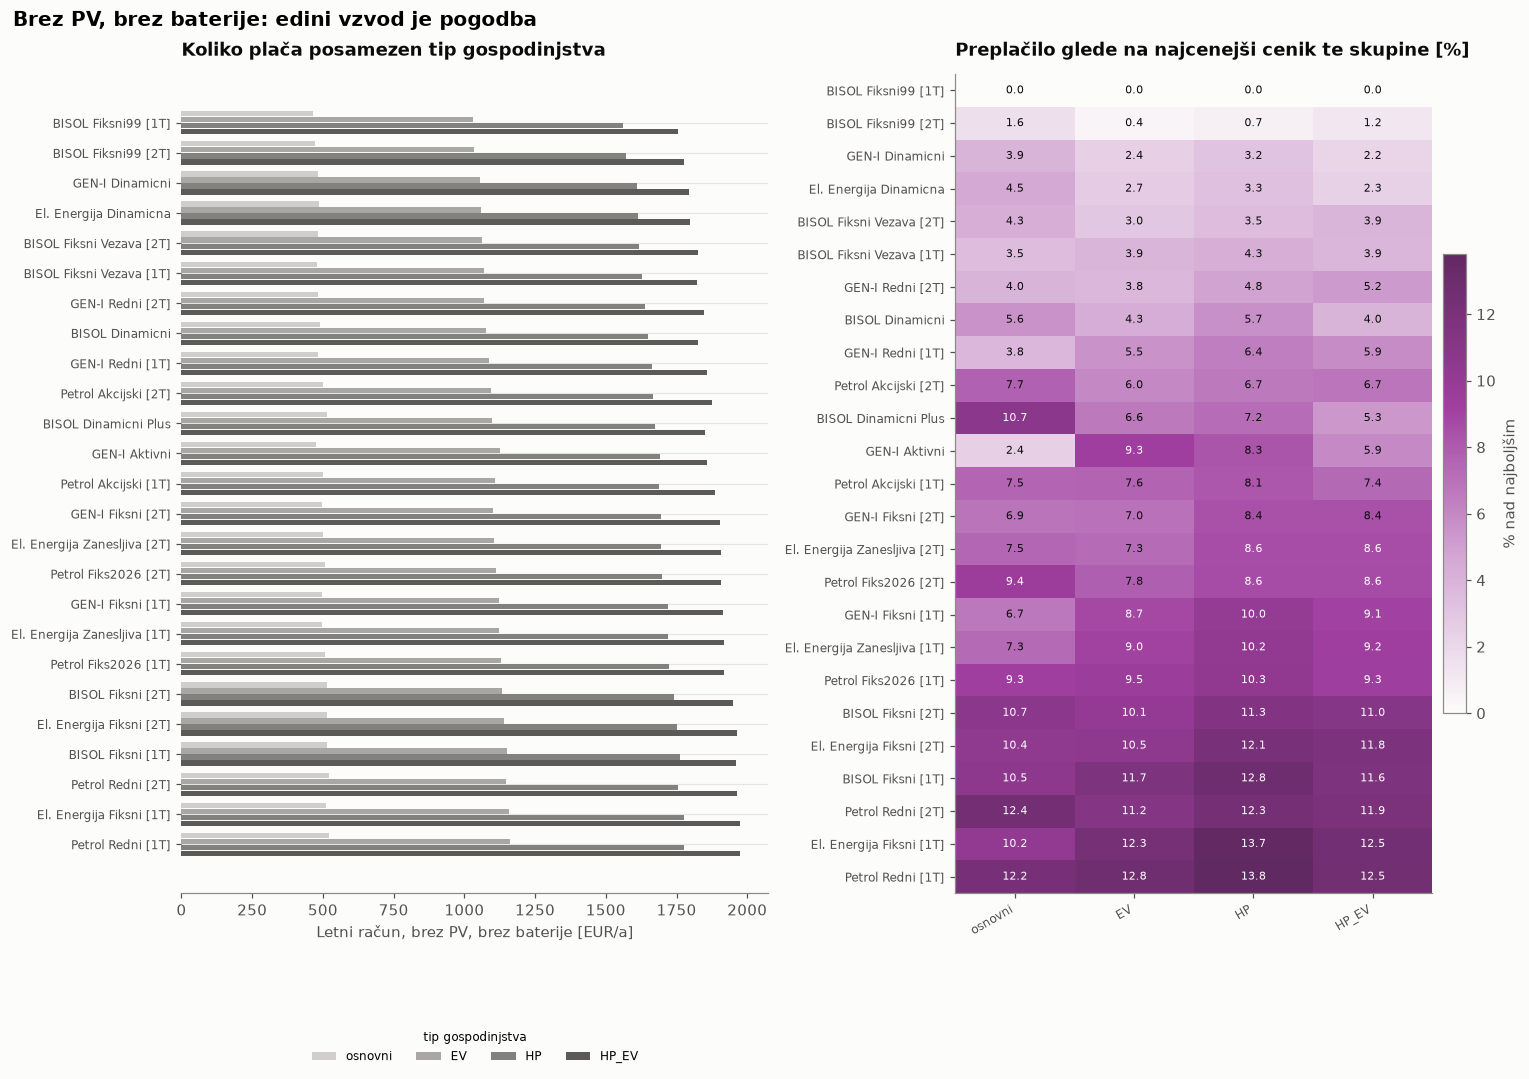

Dataset,Fluvius,Fluvius_EV,Fluvius_HP,Fluvius_HP_EV
Option,,,,
BISOL_FIKSNI99@1T,0.00,0.00,0.00,0.00
BISOL_FIKSNI99@2T,1.59,0.43,0.68,1.15
GENI_DINAMICNI,3.95,2.39,3.16,2.18
ELEN_DINAMICNA,4.55,2.66,3.34,2.34
BISOL_FIKSNI_VEZAVA@2T,4.26,2.95,3.51,3.90
BISOL_FIKSNI_VEZAVA@1T,3.51,3.89,4.27,3.87
GENI_REDNI@2T,3.96,3.77,4.83,5.18
BISOL_DINAMICNI,5.56,4.33,5.65,3.96
GENI_REDNI@1T,3.77,5.50,6.44,5.86


In [5]:
### The same ranking per household type, absolute and relative to that group's best
# Two figures, not two panels: half of \textwidth is \columnwidth, and a 25-row
# bar chart squeezed into it is unreadable. Same cell, one pf.show each.
by_group_cost = df_no_pv.pivot_table(index="Option", columns="Dataset",
                                     values="Cost_EUR").reindex(no_pv_summary.index)
by_group_rel = 100.0 * (by_group_cost / by_group_cost.min() - 1.0)

groups = list(by_group_cost.columns)
GROUP_SHADE = group_shades(groups)

fig, ax = plt.subplots(figsize=pf.figsize(ratio=rows_ratio(len(by_group_cost))))
ypos = np.arange(len(by_group_cost))[::-1]
bar_h = 0.80 / len(groups)
for i, g in enumerate(groups):
    ax.barh(ypos + 0.40 - bar_h * (i + 0.5), by_group_cost[g],
            height=bar_h * 0.86, color=GROUP_SHADE[i], label=group_label(g))
ax.set_yticks(ypos, [short_list_name(p) for p in by_group_cost.index], fontsize=8)
finish(ax, title="Brez PV, brez baterije: edini vzvod je pogodba",
       xlabel="Letni račun, brez PV, brez baterije [EUR/a]")
key_below(ax, [Patch(facecolor=c) for c in GROUP_SHADE],
          [group_label(g) for g in groups], ncol=4,
          title="tip gospodinjstva", title_fontsize=8)
ax.grid(axis="x")
ax.spines["left"].set_visible(False)
pf.show(fig, "no_pv_bill_by_group")

# Relative penalty against the cheapest list for that same household type: a
# magnitude with a floor at 0 %, so one hue ramped light -> dark. No PV means no
# export, so this chapter takes the neutral slot rather than a regime hue.
fig, ax = plt.subplots(figsize=pf.figsize(ratio=rows_ratio(len(by_group_rel),
                                                           per_row=0.30)))
overpay_heatmap(ax, by_group_rel, INK_2,
                "Brez PV: preplačilo glede na najcenejši cenik te skupine [%]",
                fig=fig, cell_fontsize=7.0)
pf.show(fig, "no_pv_overpay_by_group")

by_group_rel.round(2)

In [6]:
### Read-out: what the contract is worth next to what a battery is worth
lines = [f"{'list':24s}{'bill [EUR/a]':>14s}{'vs best [EUR/a]':>17s}{'vs best [%]':>13s}"]
for pid, row in no_pv_summary.iterrows():
    mark = "  <- cheapest" if pid == best_list else ""
    lines.append(f"{short_list_name(pid):24s}{row['Cost_EUR']:>14.2f}"
                 f"{row['Delta_EUR']:>17.2f}{row['Delta_pct']:>12.2f}%{mark}")

worst = no_pv_summary.index[-1]
switch_gain = no_pv_summary.loc[worst, "Cost_EUR"] - no_pv_summary.loc[best_list, "Cost_EUR"]
lines += [
    "",
    f"Switching from the worst option ({short_list_name(worst)}) to the best "
    f"({short_list_name(best_list)}) is worth "
    f"{switch_gain:.0f} EUR/a on average,",
    f"or {100 * switch_gain / no_pv_summary.loc[worst, 'Cost_EUR']:.1f} % of the bill -- "
    f"with no hardware, no dispatch and no battery.",
    "",
    "The three components, averaged over the households:",
    f"   energy (competitive)      {no_pv_summary['Energy_EUR'].mean():8.2f} EUR/a  "
    f"spread across lists {no_pv_summary['Energy_EUR'].max() - no_pv_summary['Energy_EUR'].min():.2f}",
    f"   fixed (agreed power etc.) {no_pv_summary['Fixed_EUR'].mean():8.2f} EUR/a  "
    f"spread across lists {no_pv_summary['Fixed_EUR'].max() - no_pv_summary['Fixed_EUR'].min():.2f}",
    f"   excess power (network)    {no_pv_summary['Excess_Power_EUR'].mean():8.2f} EUR/a  "
    f"identical on every list by construction",
    "",
    "The excess-power line is the only network item a battery can move, and it is the "
    "same number on every",
    "contract -- which is why the price list, not the network tariff, decides this "
    "question for a household with no PV.",
]

# --- 1T vs 2T, on the lists that publish both --------------------------------
pairs = sorted({hc.option_base_id(o) for o in no_pv_summary.index
                if hc.option_variant(o) != hc.VARIANT_NA})
if pairs:
    lines += ["", f"The METER, on the {len(pairs)} lists that publish both a VT/MT and an "
                  f"ET rate (2T minus 1T, so negative means 2T is cheaper):",
              f"   {'list':22s}" + "".join(f"{group_label(g):>10s}"
                                           for g in hc.NO_PV_GROUPS) + f"{'overall':>10s}"]
    by_variant = df_no_pv.pivot_table(index="Option", columns="Dataset", values="Cost_EUR")
    flips = 0
    for base in pairs:
        two, one = f"{base}@{hc.VARIANT_2T}", f"{base}@{hc.VARIANT_1T}"
        diff = by_variant.loc[two] - by_variant.loc[one]
        overall = no_pv_summary.loc[two, "Cost_EUR"] - no_pv_summary.loc[one, "Cost_EUR"]
        flips += int(diff.min() < 0 < diff.max())
        lines.append(f"   {short_list_name(base, variant=False):22s}"
                     + "".join(f"{diff[g]:>10.2f}" for g in hc.NO_PV_GROUPS)
                     + f"{overall:>10.2f}")
    lines += [
        "",
        f"The sign flips with the household type on {flips} of the {len(pairs)} lists: a "
        f"two-tariff meter only pays off for a",
        "household that moves enough demand into the MT window, and an EV or a heat pump is "
        "exactly what does that.",
        "So the meter is not a supplier-level decision -- it is a household-level one, taken "
        "on the same cenik,",
        "which is why every row above is tagged [2T] or [1T] rather than averaged into one "
        "line per list.",
        "",
        "Several lists show the SAME figure because the difference depends only on the "
        "VT-MT and VT-ET spreads,",
        "not on the price level, and most suppliers publish the same spreads "
        "(VT-MT 0.022, VT-ET 0.011). It is the",
        "level that separates those lists in the ranking above; the meter decision inside "
        "each of them is the same one.",
    ]
print("\n".join(lines))

list                      bill [EUR/a]  vs best [EUR/a]  vs best [%]
BISOL Fiksni99 [1T]            1203.22             7.36        0.66%  <- cheapest
BISOL Fiksni99 [2T]            1213.89            18.03        1.69%
GEN-I Dinamicni                1235.87            40.02        3.87%
El. Energija Dinamicna         1238.65            42.80        4.22%
BISOL Fiksni Vezava [2T]       1246.63            50.78        4.39%
BISOL Fiksni Vezava [1T]       1250.98            55.12        4.53%
GEN-I Redni [2T]               1259.12            63.26        4.99%
BISOL Dinamicni                1260.29            64.44        5.71%
GEN-I Redni [1T]               1272.66            76.80        5.85%
Petrol Akcijski [2T]           1283.20            87.35        7.59%
BISOL Dinamicni Plus           1284.16            88.30        8.74%
GEN-I Aktivni                  1288.02            92.16        7.12%
Petrol Akcijski [1T]           1295.51            99.66        8.36%
GEN-I Fiksni [2T]    

## 2. Which *samooskrba* list should a household **with PV** sign?

A different question rather than the same one with more rows: a PV household chooses from a
different catalogue and is billed under a different scheme.

All six lists carry `zahteva_pv=True`. NET metering is left out, settling once a year rather than
per interval and closed to new consents.

`si_samooskrba` nets inside the 15-minute interval and prices the residual, so the list decides
two numbers: the import price of the kWh the roof did not cover, and the buyback credit on the
surplus it could not absorb. The second is not the first in reverse — an exported kWh carries no
network charge, no levy and no VAT. On `GEN-I Samo Redni` the household imports at 0.10290
EUR/kWh of supplier price but 0.15056 delivered, and exports at 0.05390 flat. On the dynamic
lists the credit is `SIPX − pribitek` and can go negative when SIPX does, at exactly the hours a
south-facing roof produces hardest.

In [7]:
### Every PV household on every samooskrba list it could sign, zero battery
# The import rate and export credit depend only on the calendar and the market
# price, so one pass per list prices all 20.
PV_CACHE = cache_path("pv_tariff_comparison_buyback", PER_GROUP)

# Keyed on the agreed-power rule as well: a cache written against a different
# dogovorjena moc is a different bill.
cached = pd.read_csv(PV_CACHE) if PV_CACHE.exists() else None
if cached is not None and hc.agreed_power_tag(cached) != {hc.AGREED_POWER_TAG}:
    print(f"cache written under agreed power {sorted(hc.agreed_power_tag(cached))} != "
          f"{hc.AGREED_POWER_TAG!r}; recomputing")
    cached = None
if cached is not None and hc.sample_tag(cached) != {PER_GROUP}:
    print(f"cache written for per_group {sorted(hc.sample_tag(cached), key=str)} != "
          f"{PER_GROUP}; recomputing")
    cached = None

if RUN_PV or cached is None:
    df_pv = hc.pv_tariff_comparison(per_group=PER_GROUP, buyback=True, verbose=True)
    df_pv.to_csv(PV_CACHE, index=False)
else:
    df_pv = cached

pv_summary = hc.summarize_pv_tariffs(df_pv)
pv_best = pv_summary.index[0]
pv_units = df_pv.groupby(["Dataset", "Household"]).ngroups

print(f"{pv_units} households ({', '.join(hc.PV_GROUPS)}), {len(pv_summary)} samooskrba "
      f"options from {df_pv['Paket_ID'].nunique()} lists, no battery, full year under "
      f"{hc.PROSUMER_SCHEME}")
print(f"meter registers      : {df_pv['Import_kWh'].mean():.0f} kWh/a offtake, "
      f"{df_pv['Export_kWh'].mean():.0f} kWh/a injection on average "
      f"(export/import ratio {df_pv['Export_kWh'].mean() / df_pv['Import_kWh'].mean():.2f})\n")
print(f"cheapest on average  : {pv_best}  "
      f"({pv_summary.loc[pv_best, 'Cost_EUR']:.0f} EUR/a, cheapest for "
      f"{pv_summary.loc[pv_best, 'Cheapest_For']} of {pv_units} households)")
print(f"most expensive       : {pv_summary.index[-1]}  "
      f"({pv_summary['Cost_EUR'].iloc[-1]:.0f} EUR/a, "
      f"{pv_summary['Delta_pct'].iloc[-1]:.1f} % above the best available)")
print(f"spread, best to worst: "
      f"{pv_summary['Cost_EUR'].iloc[-1] - pv_summary['Cost_EUR'].iloc[0]:.0f} EUR/a")
print(f"buyback credit       : {pv_summary['Export_Credit_EUR'].min():.0f} to "
      f"{pv_summary['Export_Credit_EUR'].max():.0f} EUR/a depending on the list, "
      f"on identical exported energy")

pv_summary.rename(columns={
    "Cost_EUR": "Bill [EUR/a]",
    "Delta_EUR": "vs best [EUR/a]",
    "Delta_pct": "vs best [%]",
    "Worst_Delta_pct": "worst household [%]",
    "Energy_EUR": "energy net [EUR/a]",
    "Import_EUR": "import [EUR/a]",
    "Export_Credit_EUR": "buyback credit [EUR/a]",
    "Fixed_EUR": "fixed [EUR/a]",
    "Excess_Power_EUR": "excess power [EUR/a]",
    "Export_kWh": "exported [kWh/a]",
    "Cheapest_For": "cheapest for",
}).round(2)

  Fluvius_PV 1: 2751 kWh offtake, 3118 kWh injection
  Fluvius_PV 2: 1515 kWh offtake, 2648 kWh injection
  Fluvius_PV 3: 1073 kWh offtake, 2680 kWh injection
  Fluvius_PV 4: 1040 kWh offtake, 749 kWh injection
  Fluvius_PV 5: 1394 kWh offtake, 2864 kWh injection
  Fluvius_PV_EV 1: 4547 kWh offtake, 3449 kWh injection
  Fluvius_PV_EV 2: 2406 kWh offtake, 618 kWh injection
  Fluvius_PV_EV 3: 4811 kWh offtake, 2591 kWh injection
  Fluvius_PV_EV 4: 2575 kWh offtake, 1998 kWh injection
  Fluvius_PV_EV 5: 3939 kWh offtake, 2692 kWh injection
  Fluvius_PV_HP 1: 4908 kWh offtake, 1917 kWh injection
  Fluvius_PV_HP 2: 4672 kWh offtake, 1610 kWh injection
  Fluvius_PV_HP 3: 5289 kWh offtake, 971 kWh injection
  Fluvius_PV_HP 4: 3241 kWh offtake, 489 kWh injection
  Fluvius_PV_HP 5: 2831 kWh offtake, 3141 kWh injection
  Fluvius_PV_HP_EV 1: 3864 kWh offtake, 2343 kWh injection
  Fluvius_PV_HP_EV 2: 6874 kWh offtake, 4171 kWh injection
  Fluvius_PV_HP_EV 3: 7470 kWh offtake, 3183 kWh injection
  

,Supplier,Structure,Variant,Buyback,Households,Bill [EUR/a],vs best [EUR/a],vs best [%],worst household [%],energy net [EUR/a],fixed [EUR/a],excess power [EUR/a],import [EUR/a],buyback credit [EUR/a],exported [kWh/a],cheapest for
Option,,,,,,,,,,,,,,,,
GENI_SAMO_REDNI,GEN-I,1T: ET 0.10290,-,0.05390 flat,20,735.17,3.81,0.33,4.10,507.35,206.46,21.37,626.71,119.36,2214.52,16
GENI_SAMO_DINAMICNI,GEN-I,dynamic: SIPX + 0.01199,-,SIPX - 0.01199,20,755.12,23.76,4.81,17.19,512.95,220.80,21.37,650.57,137.62,2214.52,3
BISOL_SAMO_DINAMICNA,BISOL Energija,dynamic: SIPX + 0.01300,-,SIPX - 0.01300,20,757.48,26.12,4.94,16.98,520.29,215.82,21.37,655.67,135.38,2214.52,1
PETROL_SAMO_MESECNI,Petrol,1T: ET 0.11995,-,0.02995 flat,20,859.86,128.50,22.14,65.96,646.53,191.96,21.37,712.86,66.32,2214.52,0
GENI_SAMO_AKTIVNI,GEN-I,4 blocks: 0.04090 -> 0.19290,-,"4 blocks, 0.00190 -> 0.14990",20,873.62,142.26,23.48,55.90,645.80,206.46,21.37,747.74,101.95,2214.52,0
GENI_SAMO_FIKSNI,GEN-I,4 blocks: 0.04590 -> 0.19790,-,"4 blocks, 0.00190 -> 0.14490",20,903.87,172.51,28.32,64.02,676.05,206.46,21.37,773.01,96.96,2214.52,0


findfont: Failed to find font weight semibold, now using 700.


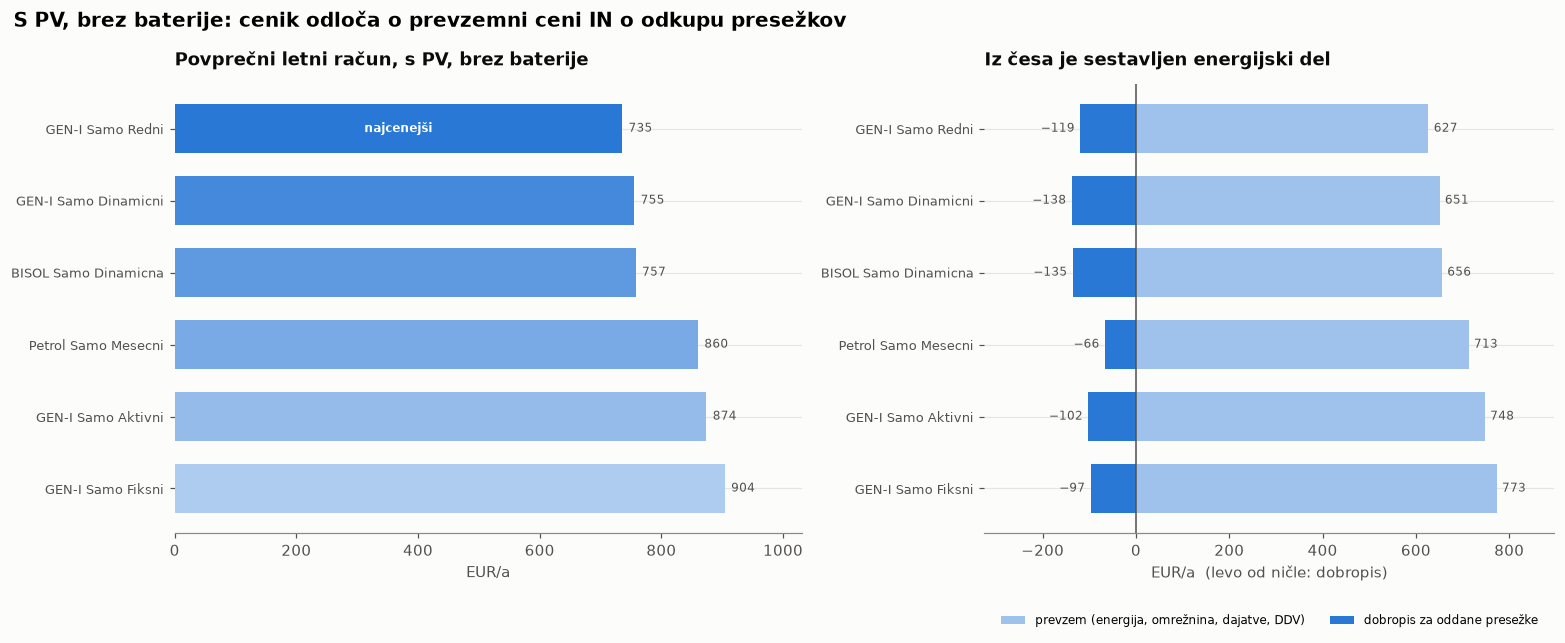

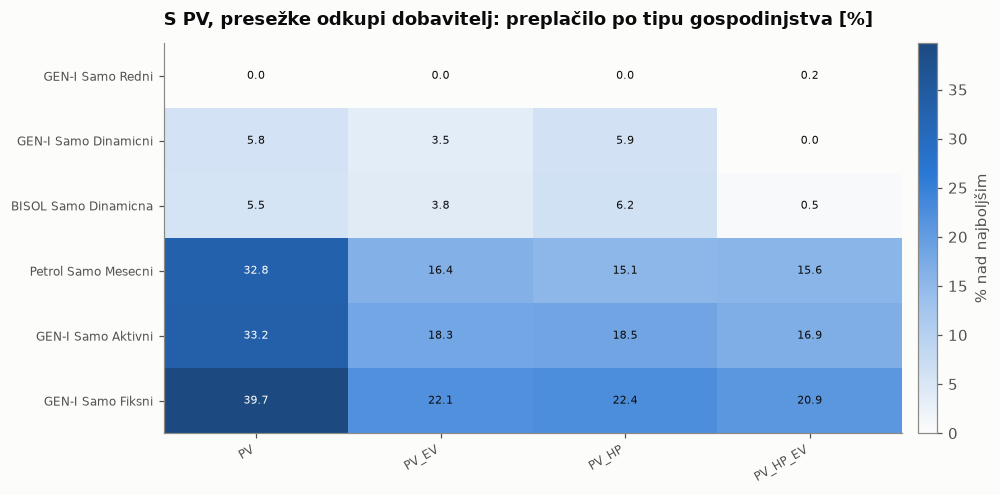

Dataset,Fluvius_PV,Fluvius_PV_EV,Fluvius_PV_HP,Fluvius_PV_HP_EV
Option,,,,
GENI_SAMO_REDNI,0.00,0.00,0.00,0.15
GENI_SAMO_DINAMICNI,5.76,3.49,5.92,0.00
BISOL_SAMO_DINAMICNA,5.49,3.75,6.17,0.51
PETROL_SAMO_MESECNI,32.81,16.40,15.11,15.64
GENI_SAMO_AKTIVNI,33.23,18.29,18.48,16.90
GENI_SAMO_FIKSNI,39.71,22.06,22.43,20.87


In [8]:
### The ranking, and where each list's bill comes from
by_group_pv = df_pv.pivot_table(index="Option", columns="Dataset",
                                values="Cost_EUR").reindex(pv_summary.index)
by_group_pv_rel = 100.0 * (by_group_pv / by_group_pv.min() - 1.0)

fig, ax = plt.subplots(figsize=pf.figsize(ratio=rows_ratio(len(pv_summary))))
ranked_bill_panel(ax, pv_summary, REGIME_COLOR["credited"],
                  "S PV, brez baterije: cenik odloča o prevzemni ceni in o odkupu presežkov",
                  "Povprečni letni račun [EUR/a]")
pf.show(fig, "pv_bill_ranking")

# The composition, on the same row order: import against what the buyback gives
# back, as two stacked parts of one bar with a 2 px surface gap.
fig, ax = plt.subplots(figsize=pf.figsize(ratio=rows_ratio(len(pv_summary))))
ypos = np.arange(len(pv_summary))[::-1]
imp = pv_summary["Import_EUR"].to_numpy()
cred = pv_summary["Export_Credit_EUR"].to_numpy()
ax.barh(ypos, imp, height=0.68, color=pf.mix(REGIME_COLOR["credited"], "#ffffff", 0.55),
        label="prevzem (energija, omrežnina, dajatve, DDV)")
ax.barh(ypos, -cred, height=0.68, color=REGIME_COLOR["credited"],
        label="dobropis za oddane presežke")
ax.axvline(0, color=INK_2, lw=1.0, zorder=4)
ax.set_yticks(ypos, [short_list_name(p) for p in pv_summary.index], fontsize=8.5)
for y, i, c in zip(ypos, imp, cred):
    ax.text(i + imp.max() * 0.015, y, f"{i:.0f}", va="center", ha="left",
            fontsize=8, color=INK_2)
    ax.text(-c - imp.max() * 0.015, y, "0" if c < 0.5 else f"−{c:.0f}",
            va="center", ha="right", fontsize=8, color=INK_2)
ax.set_xlim(-imp.max() * 0.42, imp.max() * 1.16)
finish(ax, title="S PV: iz česa je sestavljen energijski del računa",
       xlabel="EUR/a  (levo od ničle: dobropis)")
key_below(ax, [Patch(facecolor=pf.mix(REGIME_COLOR["credited"], "#ffffff", 0.55)),
               Patch(facecolor=REGIME_COLOR["credited"])],
          ["prevzem (energija, omrežnina, dajatve, DDV)",
           "dobropis za oddane presežke"], ncol=2)
ax.grid(axis="x")
ax.spines["left"].set_visible(False)
pf.show(fig, "pv_bill_composition")

fig, ax = plt.subplots(figsize=pf.figsize(ratio=rows_ratio(len(by_group_pv_rel),
                                                           per_row=0.30)))
overpay_heatmap(ax, by_group_pv_rel, REGIME_COLOR["credited"],
                "S PV, presežke odkupi dobavitelj: preplačilo po tipu gospodinjstva [%]",
                fig=fig)
pf.show(fig, "pv_overpay_by_group")

by_group_pv_rel.round(2)

In [9]:
### Read-out: the import price, the buyback, and which of the two decides it
lines = [f"{'list':26s}{'bill':>10s}{'import':>10s}{'credit':>9s}"
         f"{'fixed':>9s}{'vs best':>10s}"]
for pid, row in pv_summary.iterrows():
    mark = "  <- cheapest" if pid == pv_best else ""
    lines.append(f"{short_list_name(pid):26s}{row['Cost_EUR']:>10.2f}"
                 f"{row['Import_EUR']:>10.2f}{-row['Export_Credit_EUR']:>9.2f}"
                 f"{row['Fixed_EUR']:>9.2f}{row['Delta_pct']:>9.2f}%{mark}")

pv_worst = pv_summary.index[-1]
pv_switch = pv_summary.loc[pv_worst, "Cost_EUR"] - pv_summary.loc[pv_best, "Cost_EUR"]
imp_spread = pv_summary["Import_EUR"].max() - pv_summary["Import_EUR"].min()
# Two levers, not pooled: the full spread measures "a buyback or none", the
# spread among the lists that do buy back measures "which buyback rate".
credited_only = pv_summary[pv_summary["Export_Credit_EUR"] > 0]["Export_Credit_EUR"]
has_buyback = float(credited_only.mean())
rate_spread = float(credited_only.max() - credited_only.min())

lines += [
    "",
    f"Switching from the worst list ({short_list_name(pv_worst)}) to the best "
    f"({short_list_name(pv_best)}) is worth {pv_switch:.0f} EUR/a on average,",
    f"or {100 * pv_switch / pv_summary.loc[pv_worst, 'Cost_EUR']:.1f} % of the bill -- "
    f"with no hardware and no dispatch, on a roof the household already owns.",
    "",
    "Three levers, on identical energy, and they are not the same size:",
    f"   having ANY buyback  {has_buyback:7.2f} EUR/a  "
    f"(mean credit on the {len(credited_only)} lists that buy back, against 0 on Petrol)",
    f"   WHICH buyback rate  {rate_spread:7.2f} EUR/a  "
    f"(best to worst among those {len(credited_only)})",
    f"   which IMPORT price  {imp_spread:7.2f} EUR/a  "
    f"(best to worst across all {len(pv_summary)})",
    "",
    "So the import price and the presence of a buyback are levers of the same order, and "
    "the buyback",
    f"RATE is {imp_spread / rate_spread:.1f}x smaller than either -- which is why "
    f"{short_list_name(pv_best)} wins here on a 0.05390 flat",
    "buyback, the LOWEST rate of the five that buy back, while charging the cheapest "
    "import price.",
    "",
    f"The excess-power charge is {pv_summary['Excess_Power_EUR'].mean():.2f} EUR/a and "
    f"identical on all {len(pv_summary)} lists,",
    "because it is a network charge -- no contract can move it, and it is the one line a "
    "battery could.",
]
print("\n".join(lines))

list                            bill    import   credit    fixed   vs best
GEN-I Samo Redni              735.17    626.71  -119.36   206.46     0.33%  <- cheapest
GEN-I Samo Dinamicni          755.12    650.57  -137.62   220.80     4.81%
BISOL Samo Dinamicna          757.48    655.67  -135.38   215.82     4.94%
Petrol Samo Mesecni           859.86    712.86   -66.32   191.96    22.14%
GEN-I Samo Aktivni            873.62    747.74  -101.95   206.46    23.48%
GEN-I Samo Fiksni             903.87    773.01   -96.96   206.46    28.32%

Switching from the worst list (GEN-I Samo Fiksni) to the best (GEN-I Samo Redni) is worth 169 EUR/a on average,
or 18.7 % of the bill -- with no hardware and no dispatch, on a roof the household already owns.

Three levers, on identical energy, and they are not the same size:
   having ANY buyback   109.60 EUR/a  (mean credit on the 6 lists that buy back, against 0 on Petrol)
   WHICH buyback rate    71.30 EUR/a  (best to worst among those 6)
   which IMPOR

## 3. The same households and the same lists, with **no right to sell the surplus**

Chapter 2 priced every exported kWh at the list's own `tip_odkupa`; this chapter prices it at
zero and changes nothing else. The only term that moves is the credit on the surplus.

No catalogued list is that contract — every *samooskrba* list values a surplus at something — so
this is a counterfactual, and the gap to chapter 2 is what the export clause is worth over a
year. The control is therefore built rather than found: `hc._zero_buyback_control` takes a real
list, strikes its export clause and nothing else, and priced with the buyback on it must
reproduce this chapter's bill exactly. The cell below asserts it.

Interval-level netting is physical: within the 15 minutes it is generated, a PV kWh still
displaces an imported one whatever the contract says. A household with no buyback has not lost
its roof, only the residue the roof could not absorb in the quarter-hour it appeared.

With every list crediting exports at zero the six differ only in import price and monthly fee, so
the ranking must compress. Whether it re-orders is a question about this catalogue: it re-orders
only where the list with the better buyback is not also the cheaper importer.

In [10]:
### The same 20 PV households, exported kWh priced at zero
PV_NOSALE_CACHE = cache_path("pv_tariff_comparison_nosale", PER_GROUP)

cached = pd.read_csv(PV_NOSALE_CACHE) if PV_NOSALE_CACHE.exists() else None
if cached is not None and hc.agreed_power_tag(cached) != {hc.AGREED_POWER_TAG}:
    print(f"cache written under agreed power {sorted(hc.agreed_power_tag(cached))} != "
          f"{hc.AGREED_POWER_TAG!r}; recomputing")
    cached = None
if cached is not None and hc.sample_tag(cached) != {PER_GROUP}:
    print(f"cache written for per_group {sorted(hc.sample_tag(cached), key=str)} != "
          f"{PER_GROUP}; recomputing")
    cached = None

if RUN_PV_NOSALE or cached is None:
    df_pv0 = hc.pv_tariff_comparison(per_group=PER_GROUP, buyback=False, verbose=True)
    df_pv0.to_csv(PV_NOSALE_CACHE, index=False)
else:
    df_pv0 = cached

pv0_summary = hc.summarize_pv_tariffs(df_pv0)
pv0_best = pv0_summary.index[0]

# --- the two checks that say the flag did only what it claims -----------------
# 1. Every exported kWh is credited at zero, on every list and every household.
assert float(df_pv0["Export_Credit_EUR"].abs().max()) == 0.0

# 2. A list whose export clause is struck cannot notice the flag. No catalogued
#    list is that list, so the control is built: the same package with
#    tip_odkupa=NI, priced WITH the buyback on. Any drift would mean the flag is
#    reaching the import side, the fixed charge or the peak.
key = ["Dataset", "Household", "Option"]
control = hc._zero_buyback_control(prosumer_options[0])
df_ctl = hc.pv_tariff_comparison(per_group=PER_GROUP, options=[control], buyback=True)
a = df_ctl.set_index(key)["Cost_EUR"].sort_index()
b = (df_pv0[df_pv0["Option"] == hc.option_base_id(control)]
     .assign(Option=control).set_index(key)["Cost_EUR"].sort_index())
drift = float((a - b).abs().max())
assert drift < 1e-9, f"{control} moved by {drift:.2e} EUR when only the buyback changed"

# 3. And the only thing that moved anywhere else is the credit itself.
joined = df_pv.set_index(key).join(df_pv0.set_index(key), rsuffix="_0")
residual = float((joined["Cost_EUR_0"]
                  - (joined["Cost_EUR"] + joined["Export_Credit_EUR"])).abs().max())
assert residual < 1e-9, f"import/fixed/peak moved too, by up to {residual:.2e} EUR"

print(f"checks passed: the zero-buyback control on {hc.option_base_id(control)} "
      f"reproduces buyback=False to {drift:.1e} EUR,\nand every other option moved by "
      f"exactly its lost credit ({residual:.1e} EUR residual)\n")

print(f"cheapest on average  : {pv0_best}  "
      f"({pv0_summary.loc[pv0_best, 'Cost_EUR']:.0f} EUR/a, cheapest for "
      f"{pv0_summary.loc[pv0_best, 'Cheapest_For']} of {pv_units} households)")
print(f"most expensive       : {pv0_summary.index[-1]}  "
      f"({pv0_summary['Cost_EUR'].iloc[-1]:.0f} EUR/a, "
      f"{pv0_summary['Delta_pct'].iloc[-1]:.1f} % above the best available)")
print(f"spread, best to worst: "
      f"{pv0_summary['Cost_EUR'].iloc[-1] - pv0_summary['Cost_EUR'].iloc[0]:.0f} EUR/a"
      f"  (was {pv_summary['Cost_EUR'].iloc[-1] - pv_summary['Cost_EUR'].iloc[0]:.0f} "
      f"EUR/a with the buyback -- the spread compresses, as it must)")
rank_before = list(pv_summary.index)
rank_after = list(pv0_summary.index)
moved = [p for p in rank_after if rank_before.index(p) != rank_after.index(p)]
print(f"ranking              : {'unchanged' if not moved else 're-ordered'}"
      + (f" -- {', '.join(short_list_name(p) for p in moved)} change place"
         if moved else ""))

pv0_summary.rename(columns={
    "Cost_EUR": "Bill [EUR/a]",
    "Delta_EUR": "vs best [EUR/a]",
    "Delta_pct": "vs best [%]",
    "Worst_Delta_pct": "worst household [%]",
    "Energy_EUR": "energy net [EUR/a]",
    "Import_EUR": "import [EUR/a]",
    "Export_Credit_EUR": "buyback credit [EUR/a]",
    "Fixed_EUR": "fixed [EUR/a]",
    "Excess_Power_EUR": "excess power [EUR/a]",
    "Export_kWh": "exported [kWh/a]",
    "Cheapest_For": "cheapest for",
}).round(2)

  Fluvius_PV 1: 2751 kWh offtake, 3118 kWh injection
  Fluvius_PV 2: 1515 kWh offtake, 2648 kWh injection
  Fluvius_PV 3: 1073 kWh offtake, 2680 kWh injection
  Fluvius_PV 4: 1040 kWh offtake, 749 kWh injection
  Fluvius_PV 5: 1394 kWh offtake, 2864 kWh injection
  Fluvius_PV_EV 1: 4547 kWh offtake, 3449 kWh injection
  Fluvius_PV_EV 2: 2406 kWh offtake, 618 kWh injection
  Fluvius_PV_EV 3: 4811 kWh offtake, 2591 kWh injection
  Fluvius_PV_EV 4: 2575 kWh offtake, 1998 kWh injection
  Fluvius_PV_EV 5: 3939 kWh offtake, 2692 kWh injection
  Fluvius_PV_HP 1: 4908 kWh offtake, 1917 kWh injection
  Fluvius_PV_HP 2: 4672 kWh offtake, 1610 kWh injection
  Fluvius_PV_HP 3: 5289 kWh offtake, 971 kWh injection
  Fluvius_PV_HP 4: 3241 kWh offtake, 489 kWh injection
  Fluvius_PV_HP 5: 2831 kWh offtake, 3141 kWh injection
  Fluvius_PV_HP_EV 1: 3864 kWh offtake, 2343 kWh injection
  Fluvius_PV_HP_EV 2: 6874 kWh offtake, 4171 kWh injection
  Fluvius_PV_HP_EV 3: 7470 kWh offtake, 3183 kWh injection
  

,Supplier,Structure,Variant,Buyback,Households,Bill [EUR/a],vs best [EUR/a],vs best [%],worst household [%],energy net [EUR/a],fixed [EUR/a],excess power [EUR/a],import [EUR/a],buyback credit [EUR/a],exported [kWh/a],cheapest for
Option,,,,,,,,,,,,,,,,
GENI_SAMO_REDNI,GEN-I,1T: ET 0.10290,-,zeroed,20,854.53,0.79,0.05,0.88,626.71,206.46,21.37,626.71,0.0,2214.52,18
GENI_SAMO_DINAMICNI,GEN-I,dynamic: SIPX + 0.01199,-,zeroed,20,892.74,39.00,6.08,12.63,650.57,220.80,21.37,650.57,0.0,2214.52,2
BISOL_SAMO_DINAMICNA,BISOL Energija,dynamic: SIPX + 0.01300,-,zeroed,20,892.86,39.12,5.86,11.24,655.67,215.82,21.37,655.67,0.0,2214.52,0
PETROL_SAMO_MESECNI,Petrol,1T: ET 0.11995,-,zeroed,20,926.19,72.44,7.52,11.58,712.86,191.96,21.37,712.86,0.0,2214.52,0
GENI_SAMO_AKTIVNI,GEN-I,4 blocks: 0.04090 -> 0.19290,-,zeroed,20,975.56,121.82,14.19,19.00,747.74,206.46,21.37,747.74,0.0,2214.52,0
GENI_SAMO_FIKSNI,GEN-I,4 blocks: 0.04590 -> 0.19790,-,zeroed,20,1000.83,147.09,17.06,22.31,773.01,206.46,21.37,773.01,0.0,2214.52,0


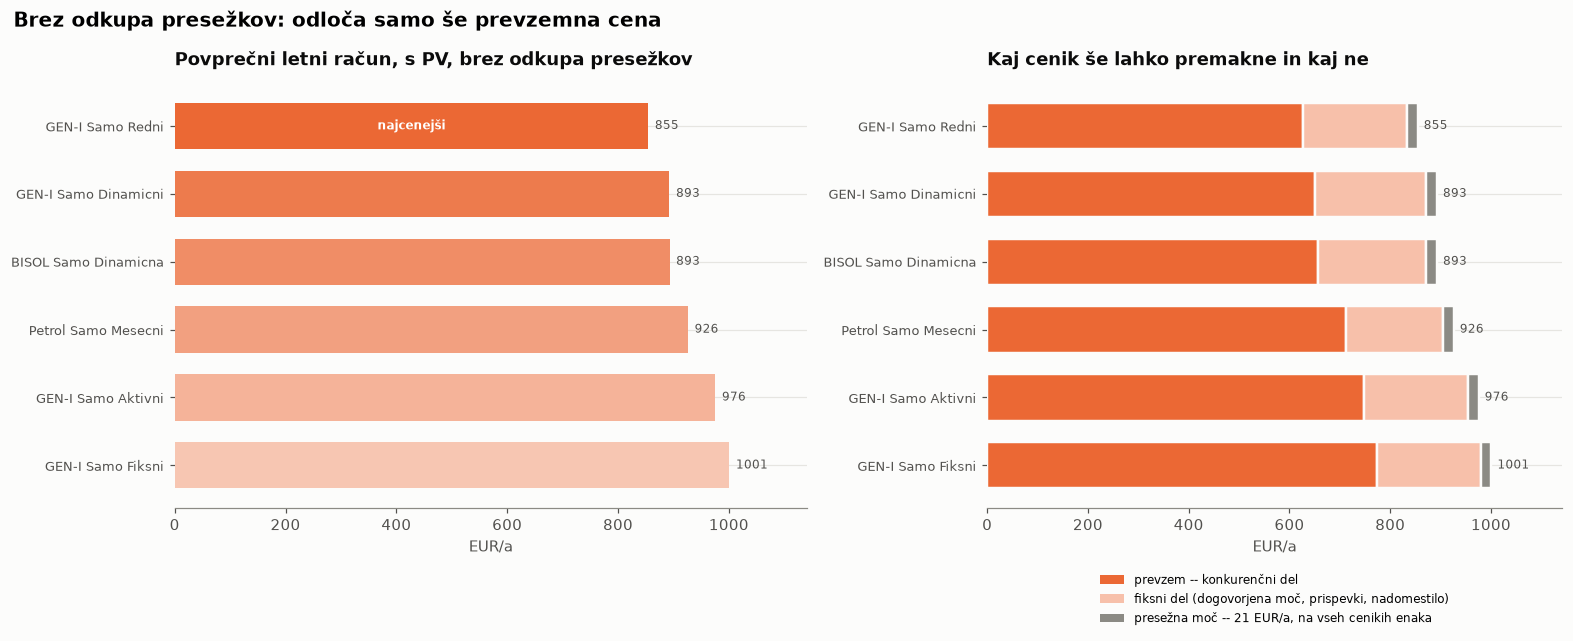

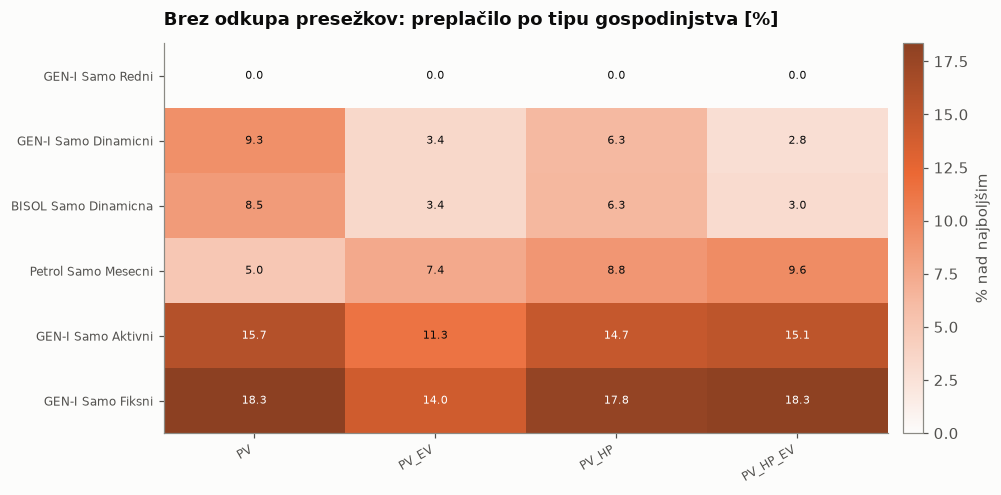

Dataset,Fluvius_PV,Fluvius_PV_EV,Fluvius_PV_HP,Fluvius_PV_HP_EV
Option,,,,
GENI_SAMO_REDNI,0.00,0.00,0.00,0.00
GENI_SAMO_DINAMICNI,9.30,3.43,6.30,2.77
BISOL_SAMO_DINAMICNA,8.45,3.37,6.32,3.04
PETROL_SAMO_MESECNI,4.95,7.42,8.79,9.60
GENI_SAMO_AKTIVNI,15.71,11.33,14.69,15.13
GENI_SAMO_FIKSNI,18.35,14.02,17.78,18.25


In [11]:
### The ranking with no buyback, and how much of the bill is now beyond reach
by_group_pv0 = df_pv0.pivot_table(index="Option", columns="Dataset",
                                  values="Cost_EUR").reindex(pv0_summary.index)
by_group_pv0_rel = 100.0 * (by_group_pv0 / by_group_pv0.min() - 1.0)

fig, ax = plt.subplots(figsize=pf.figsize(ratio=rows_ratio(len(pv0_summary))))
ranked_bill_panel(ax, pv0_summary, REGIME_COLOR["nosale"],
                  "Brez odkupa presežkov: odloča samo še prevzemna cena",
                  "Povprečni letni račun, s PV, brez odkupa presežkov [EUR/a]")
pf.show(fig, "pv_nosale_bill_ranking")

# With the credit gone the bill is import + fixed + excess, and only the first
# two differ between lists, so the bar splits at what a contract can move.
fig, ax = plt.subplots(figsize=pf.figsize(ratio=rows_ratio(len(pv0_summary))))
ypos = np.arange(len(pv0_summary))[::-1]
imp0 = pv0_summary["Import_EUR"].to_numpy()
fix0 = pv0_summary["Fixed_EUR"].to_numpy()
exc0 = pv0_summary["Excess_Power_EUR"].to_numpy()
# edgecolor=SURFACE gives the 2 px gap between stacked fills.
seg = dict(height=0.68, edgecolor=SURFACE, linewidth=1.6)
ax.barh(ypos, imp0, color=REGIME_COLOR["nosale"], **seg)
ax.barh(ypos, fix0, left=imp0,
        color=pf.mix(REGIME_COLOR["nosale"], "#ffffff", 0.58), **seg)
ax.barh(ypos, exc0, left=imp0 + fix0, color=MUTED, **seg)
ax.set_yticks(ypos, [short_list_name(p) for p in pv0_summary.index], fontsize=8.5)
bar_labels(ax, ypos, (imp0 + fix0 + exc0))
ax.set_xlim(0, (imp0 + fix0 + exc0).max() * 1.14)
finish(ax, title="Kaj cenik še lahko premakne in kaj ne", xlabel="EUR/a")
# Explicit handles: the bars' SURFACE edge would read as a hollow swatch at
# legend size.
key_below(
    ax,
    [Patch(facecolor=REGIME_COLOR["nosale"], edgecolor="none"),
     Patch(facecolor=pf.mix(REGIME_COLOR["nosale"], "#ffffff", 0.58), edgecolor="none"),
     Patch(facecolor=MUTED, edgecolor="none")],
    ["prevzem -- konkurenčni del",
     "fiksni del (dogovorjena moč, prispevki, nadomestilo)",
     f"presežna moč -- {exc0.mean():.0f} EUR/a, na vseh cenikih enaka"],
    ncol=1)
ax.grid(axis="x")
ax.spines["left"].set_visible(False)
pf.show(fig, "pv_nosale_bill_composition")

fig, ax = plt.subplots(figsize=pf.figsize(ratio=rows_ratio(len(by_group_pv0_rel),
                                                           per_row=0.30)))
overpay_heatmap(ax, by_group_pv0_rel, REGIME_COLOR["nosale"],
                "Brez odkupa presežkov: preplačilo po tipu gospodinjstva [%]", fig=fig)
pf.show(fig, "pv_nosale_overpay_by_group")

by_group_pv0_rel.round(2)

In [12]:
### Read-out: what is left to choose between when the surplus is worth nothing
lines = [f"{'list':26s}{'bill':>10s}{'import':>10s}{'fixed':>9s}{'vs best':>10s}"]
for pid, row in pv0_summary.iterrows():
    mark = "  <- cheapest" if pid == pv0_best else ""
    lines.append(f"{short_list_name(pid):26s}{row['Cost_EUR']:>10.2f}"
                 f"{row['Import_EUR']:>10.2f}{row['Fixed_EUR']:>9.2f}"
                 f"{row['Delta_pct']:>9.2f}%{mark}")

pv0_worst = pv0_summary.index[-1]
pv0_switch = pv0_summary.loc[pv0_worst, "Cost_EUR"] - pv0_summary.loc[pv0_best, "Cost_EUR"]
lines += [
    "",
    f"Best to worst is now {pv0_switch:.0f} EUR/a "
    f"({100 * pv0_switch / pv0_summary.loc[pv0_worst, 'Cost_EUR']:.1f} % of the bill), "
    f"against {pv_switch:.0f} EUR/a in chapter 2.",
    f"The buyback was carrying "
    f"{100 * (pv_switch - pv0_switch) / pv_switch:.0f} % of the spread between the best "
    f"and the worst contract.",
    "",
    "The bill, averaged over the households and the lists:",
    f"   import (competitive)      {pv0_summary['Import_EUR'].mean():8.2f} EUR/a  "
    f"spread across lists {pv0_summary['Import_EUR'].max() - pv0_summary['Import_EUR'].min():.2f}",
    f"   fixed (agreed power etc.) {pv0_summary['Fixed_EUR'].mean():8.2f} EUR/a  "
    f"spread across lists {pv0_summary['Fixed_EUR'].max() - pv0_summary['Fixed_EUR'].min():.2f}",
    f"   excess power (network)    {pv0_summary['Excess_Power_EUR'].mean():8.2f} EUR/a  "
    f"identical on every list by construction",
    "",
    f"And the surplus that is now worth nothing: "
    f"{df_pv0['Export_kWh'].mean():.0f} kWh/a per household, which the best chapter-2 "
    f"list would have paid",
    f"{pv_summary.loc[pv_best, 'Export_Credit_EUR']:.0f} EUR/a for "
    f"({100 * pv_summary.loc[pv_best, 'Export_Credit_EUR'] / pv_summary.loc[pv_best, 'Cost_EUR']:.0f} "
    f"% of that bill).",
]
print("\n".join(lines))

list                            bill    import    fixed   vs best
GEN-I Samo Redni              854.53    626.71   206.46     0.05%  <- cheapest
GEN-I Samo Dinamicni          892.74    650.57   220.80     6.08%
BISOL Samo Dinamicna          892.86    655.67   215.82     5.86%
Petrol Samo Mesecni           926.19    712.86   191.96     7.52%
GEN-I Samo Aktivni            975.56    747.74   206.46    14.19%
GEN-I Samo Fiksni            1000.83    773.01   206.46    17.06%

Best to worst is now 146 EUR/a (14.6 % of the bill), against 169 EUR/a in chapter 2.
The buyback was carrying 13 % of the spread between the best and the worst contract.

The bill, averaged over the households and the lists:
   import (competitive)        694.43 EUR/a  spread across lists 146.30
   fixed (agreed power etc.)   207.99 EUR/a  spread across lists 28.84
   excess power (network)       21.37 EUR/a  identical on every list by construction

And the surplus that is now worth nothing: 2215 kWh/a per household, w

## 4. What the right to sell the surplus is worth — best 3 and worst 3 contracts

Chapters 2 and 3 are two contracts for the same house; this chapter puts them on the same row.
The middle of the ranking is dropped — it carries no finding the ends do not.

Ranking is by the credited bill, because that is the contract a household with a roof would be
offered; each row carries its rank in the zero-export ranking too, so a re-order is visible
rather than hidden by the sort.

Three things this settles that neither chapter can alone:

1. **The euro value of the buyback**, per contract — the horizontal distance between the dots.
2. **Whether the right to sell changes which contract to sign.** If the ranking survives zeroing
   the credit, the two decisions are separable.
3. **What the metering variant is worth next to it.** `Petrol Samooskrba` appears as both `[2T]`
   and `[1T]`, so the gap between those rows is the price of the meter.

The zero-export bill is always the higher of the two, so the gap is the maximum a household
should pay per year for a supplier that buys its surplus.

In [13]:
### Best 3 and worst 3 contracts, each under both regimes
TOP_N = 6
ranked = list(pv_summary.index)                 # by credited bill, cheapest first
best = ranked[:TOP_N]
worst = ranked[-TOP_N:]
# With <= 2*TOP_N options the two ends would overlap.
worst = [o for o in worst if o not in best]
shortlist = best + worst
middle = [o for o in ranked if o not in shortlist]

rank0 = {o: i for i, o in enumerate(pv0_summary.index)}
head = pd.DataFrame({
    "Credited_EUR": pv_summary.loc[shortlist, "Cost_EUR"],
    "NoSale_EUR": pv0_summary.loc[shortlist, "Cost_EUR"],
    "Variant": [hc.option_variant(o) for o in shortlist],
    "Structure": [hc.tariff_structure_label(o) for o in shortlist],
    "Buyback": [hc.buyback_rate_label(o) for o in shortlist],
    "End": ["best" if o in best else "worst" for o in shortlist],
    "Rank_Credited": [ranked.index(o) + 1 for o in shortlist],
    "Rank_NoSale": [rank0[o] + 1 for o in shortlist],
})
head["Worth_EUR"] = head["NoSale_EUR"] - head["Credited_EUR"]
head["Worth_pct"] = 100.0 * head["Worth_EUR"] / head["NoSale_EUR"]

print(f"{len(pv_summary)} samooskrba options ranked by the credited bill; showing the "
      f"best {len(best)} and worst {len(worst)}")
print(f"   best  : {', '.join(short_list_name(o) for o in best)}")
print(f"   worst : {', '.join(short_list_name(o) for o in worst)}")
if middle:
    print(f"   not shown ({len(middle)}): "
          f"{', '.join(short_list_name(o) for o in middle)}")
reordered = head[head["Rank_Credited"] != head["Rank_NoSale"]]
print(f"\nranking under the two regimes: "
      f"{'identical' if reordered.empty else 'differs on ' + ', '.join(short_list_name(o) for o in reordered.index)}")

head.rename(index=short_list_name).rename(columns={
    "Credited_EUR": "with buyback [EUR/a]",
    "NoSale_EUR": "no sale [EUR/a]",
    "Variant": "meter",
    "Structure": "billed on",
    "Buyback": "buyback terms",
    "End": "end of ranking",
    "Rank_Credited": "rank, credited",
    "Rank_NoSale": "rank, no sale",
    "Worth_EUR": "right to sell worth [EUR/a]",
    "Worth_pct": "worth [% of bill]",
}).round(2)

6 samooskrba options ranked by the credited bill; showing the best 6 and worst 0
   best  : GEN-I Samo Redni, GEN-I Samo Dinamicni, BISOL Samo Dinamicna, Petrol Samo Mesecni, GEN-I Samo Aktivni, GEN-I Samo Fiksni
   worst : 

ranking under the two regimes: identical


,with buyback [EUR/a],no sale [EUR/a],meter,billed on,buyback terms,end of ranking,"rank, credited","rank, no sale",right to sell worth [EUR/a],worth [% of bill]
Option,,,,,,,,,,
GEN-I Samo Redni,735.17,854.53,-,1T: ET 0.10290,0.05390 flat,best,1,1,119.36,13.97
GEN-I Samo Dinamicni,755.12,892.74,-,dynamic: SIPX + 0.01199,SIPX - 0.01199,best,2,2,137.62,15.42
BISOL Samo Dinamicna,757.48,892.86,-,dynamic: SIPX + 0.01300,SIPX - 0.01300,best,3,3,135.38,15.16
Petrol Samo Mesecni,859.86,926.19,-,1T: ET 0.11995,0.02995 flat,best,4,4,66.32,7.16
GEN-I Samo Aktivni,873.62,975.56,-,4 blocks: 0.04090 -> 0.19290,"4 blocks, 0.00190 -> 0.14990",best,5,5,101.95,10.45
GEN-I Samo Fiksni,903.87,1000.83,-,4 blocks: 0.04590 -> 0.19790,"4 blocks, 0.00190 -> 0.14490",best,6,6,96.96,9.69


findfont: Failed to find font weight semibold, now using 700.


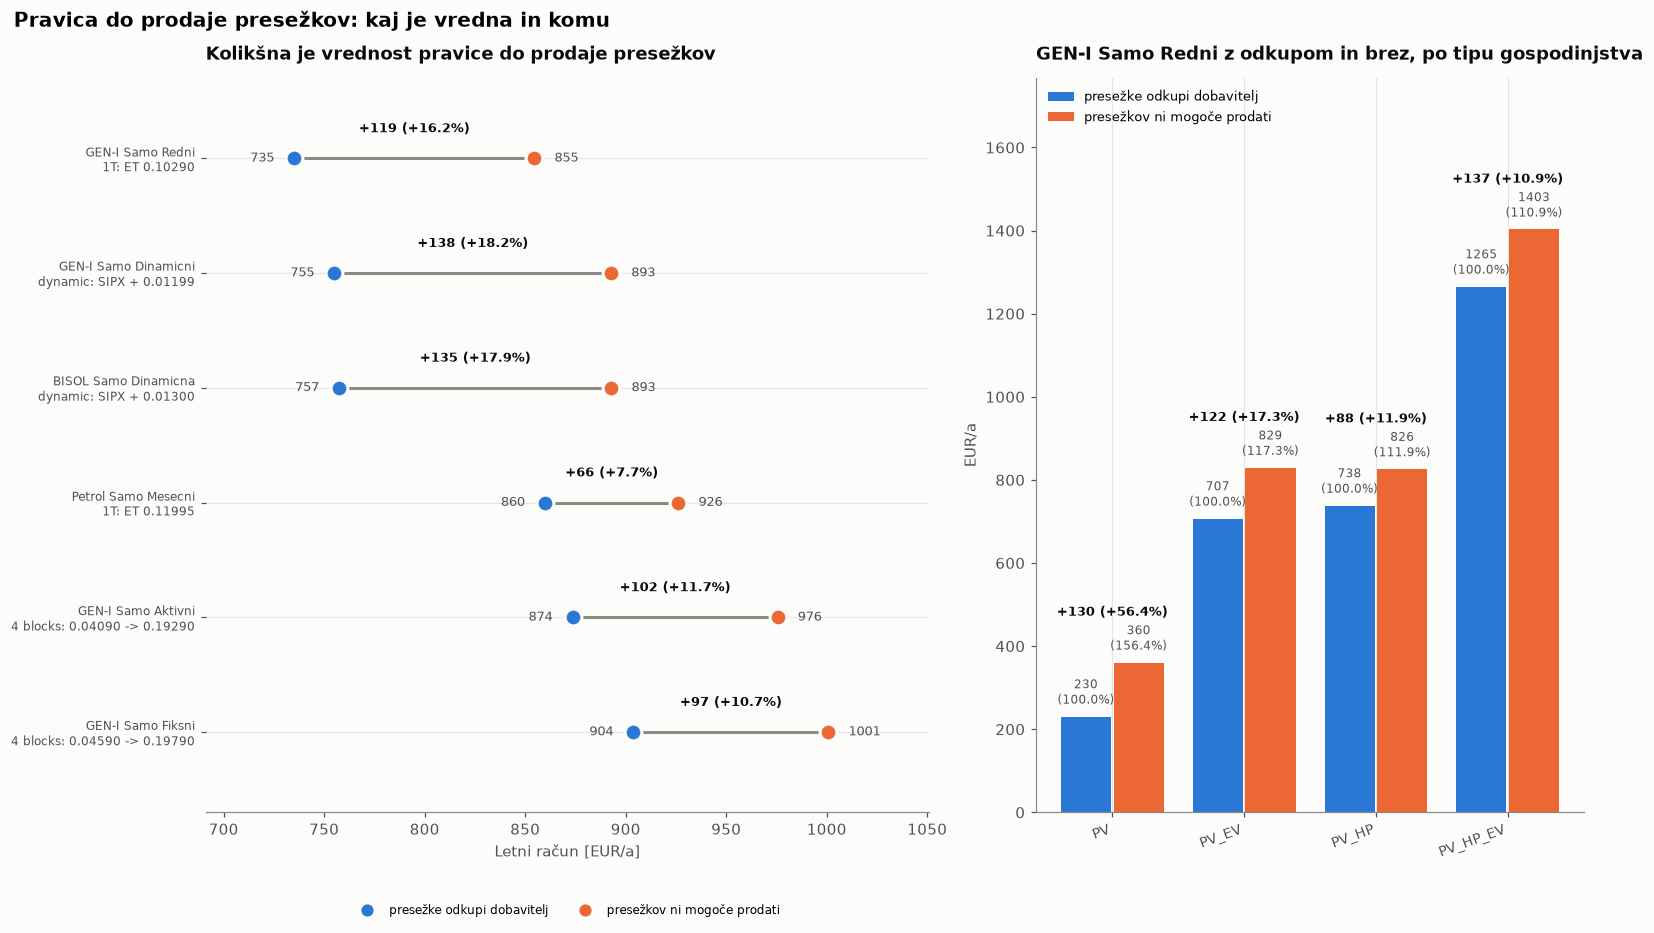

,credited,nosale,Worth_EUR,Export_kWh
Dataset,,,,
Fluvius_PV,230.4,360.4,130.0,2411.8
Fluvius_PV_EV,706.9,829.2,122.3,2269.6
Fluvius_PV_HP,738.2,825.8,87.6,1625.7
Fluvius_PV_HP_EV,1265.2,1402.7,137.5,2551.0


In [14]:
### The two contracts on the same axis: one row per contract, one dot per regime
# A dumbbell rather than paired bars: the quantity of interest is the distance
# between two states of the same household. Both dots are labelled.
fig, ax = plt.subplots(figsize=pf.figsize(
    ratio=rows_ratio(len(head), per_row=0.62, floor=3.6)))

ypos = np.arange(len(head))[::-1]
span = head["NoSale_EUR"].max()
for y, (opt, row) in zip(ypos, head.iterrows()):
    ax.plot([row["Credited_EUR"], row["NoSale_EUR"]], [y, y],
            color=MUTED, lw=2.0, zorder=1, solid_capstyle="round")
    if row["Worth_EUR"] < 0.5:
        # A list that never bought surpluses lands both regimes on the same
        # euro, so the marker is split in half rather than overdrawn.
        for regime, side in (("credited", "left"), ("nosale", "right")):
            ax.plot(row["Credited_EUR"], y, marker="o", ms=11, ls="",
                    color=REGIME_COLOR[regime], fillstyle=side,
                    mec=SURFACE, mew=1.2, zorder=3)
    else:
        # 2 px surface ring on each mark so a dot never dissolves into the connector
        for value, regime in ((row["Credited_EUR"], "credited"),
                              (row["NoSale_EUR"], "nosale")):
            ax.plot(value, y, marker="o", ms=11, color=REGIME_COLOR[regime],
                    mec=SURFACE, mew=2.0, zorder=3)
    ax.text(row["Credited_EUR"] - span * 0.010, y, f"{row['Credited_EUR']:.0f}",
            va="center", ha="right", fontsize=8.5, color=INK_2)
    if row["Worth_EUR"] >= 0.5:
        worth_pct = row["Worth_EUR"] / row["Credited_EUR"] * 100 if row["Credited_EUR"] else 0
        ax.text(row["NoSale_EUR"] + span * 0.010, y, f"{row['NoSale_EUR']:.0f}",
                va="center", ha="left", fontsize=8.5, color=INK_2)
        ax.text((row["Credited_EUR"] + row["NoSale_EUR"]) / 2, y + 0.20,
                f"+{row['Worth_EUR']:.0f} (+{worth_pct:.1f}%)",
                va="bottom", ha="center", fontsize=8.5, color=INK,
                fontweight="semibold")
    else:
        ax.text((row["Credited_EUR"] + row["NoSale_EUR"]) / 2, y + 0.20,
                "brez odkupa",
                va="bottom", ha="center", fontsize=8.5, color=INK,
                fontweight="semibold")

# The row label carries the contract, the meter variant and the billing scheme.
ax.set_yticks(ypos, [f"{short_list_name(o)}\n{head.loc[o, 'Structure']}"
                     for o in head.index], fontsize=8)
# A rule between the best and worst blocks: the middle of the ranking is
# missing, and a continuous axis would imply it is not.
if len(best) < len(head):
    ax.axhline(ypos[len(best) - 1] - 0.5, color=MUTED, lw=1.0, ls=(0, (4, 3)))
    ax.text(head["Credited_EUR"].min() * 0.955, ypos[len(best) - 1] - 0.42,
            f"najboljši {len(best)}", va="bottom", ha="left", fontsize=8,
            color=MUTED, style="italic")
    ax.text(head["Credited_EUR"].min() * 0.955, ypos[len(best) - 1] - 0.58,
            f"najslabši {len(worst)}" + (f"  ({len(middle)} vmesnih ni prikazanih)"
                                         if middle else ""),
            va="top", ha="left", fontsize=8, color=MUTED, style="italic")
ax.set_xlim(head["Credited_EUR"].min() * 0.94, span * 1.05)
ax.set_ylim(-0.7, len(head) - 0.3)
finish(ax, title="Kolikšna je vrednost pravice do prodaje presežkov",
       xlabel="Letni račun [EUR/a]")
ax.grid(axis="x")
ax.spines["left"].set_visible(False)
key_below(ax,
          [plt.Line2D([], [], marker="o", ls="", ms=10, mec=SURFACE, mew=2.0,
                      color=REGIME_COLOR[r]) for r in ("credited", "nosale")],
          [REGIME_LABEL[r] for r in ("credited", "nosale")], ncol=2)
pf.show(fig, "export_right_worth")

# Per household type, on the best contract of each regime: who the buyback
# matters to.
best_pair = {"credited": (pv_best, df_pv), "nosale": (pv0_best, df_pv0)}
groups_pv = list(hc.PV_GROUPS)
by_group_regime = pd.DataFrame({
    regime: (frame[frame["Option"] == opt]
             .groupby("Dataset")["Cost_EUR"].mean().reindex(groups_pv))
    for regime, (opt, frame) in best_pair.items()
})

fig, ax = plt.subplots()
xpos = np.arange(len(groups_pv))
bar_w = 0.38
credited_values = by_group_regime["credited"].to_numpy()
for i, regime in enumerate(("credited", "nosale")):
    ax.bar(xpos + (i - 0.5) * (bar_w + 0.02), by_group_regime[regime],
           width=bar_w,
           color=REGIME_COLOR[regime], label=REGIME_LABEL[regime])
    for x, v, base in zip(xpos + (i - 0.5) * (bar_w + 0.02),
                          by_group_regime[regime], credited_values):
        pct = v / base * 100 if base else 0
        ax.text(x, v + by_group_regime.to_numpy().max() * 0.015,
                f"{v:.0f}\n({pct:.1f}%)", ha="center",
                va="bottom", fontsize=8, color=INK_2)
# The delta is written between the pair rather than left to be subtracted.
for x, (lo, hi) in zip(xpos, zip(by_group_regime["credited"],
                                 by_group_regime["nosale"])):
    pct = (hi - lo) / lo * 100 if lo else 0
    ax.text(x, hi + by_group_regime.to_numpy().max() * 0.075,
            f"+{hi - lo:.0f} (+{pct:.1f}%)", ha="center", va="bottom", fontsize=8.5,
            color=INK, fontweight="semibold")
ax.set_xticks(xpos, [group_label(g) for g in groups_pv],
              rotation=20, ha="right", fontsize=9)
ax.set_ylim(0, by_group_regime.to_numpy().max() * 1.26)
finish(ax,
       title=(f"{short_list_name(pv_best)} z odkupom in brez, po tipu gospodinjstva"
              if pv_best == pv0_best else
              "Na najcenejšem ceniku vsake možnosti, po tipu gospodinjstva"),
       ylabel="EUR/a", yfmt=EUR)
ax.legend(fontsize=8.5, loc="upper left")
ax.grid(axis="y")
pf.show(fig, "export_right_by_group")

by_group_regime.assign(
    Worth_EUR=lambda d: d["nosale"] - d["credited"],
    Export_kWh=df_pv.groupby("Dataset")["Export_kWh"].mean().reindex(groups_pv),
).round(1)

In [15]:
### Read-out: is the contract choice separable from the right to sell?
per_hh = (df_pv.set_index(["Dataset", "Household", "Option"])["Cost_EUR"]
          .rename("credited").to_frame()
          .join(df_pv0.set_index(["Dataset", "Household", "Option"])["Cost_EUR"]
                .rename("nosale")))
per_hh["worth"] = per_hh["nosale"] - per_hh["credited"]
best_worth = per_hh.xs(pv_best, level="Option")["worth"]
export_by_unit = df_pv.groupby(["Dataset", "Household"])["Export_kWh"].first()
rel_share = pd.DataFrame({
    "credited": df_pv[df_pv["Option"] == pv_best].groupby("Dataset")["Cost_EUR"].mean(),
    "nosale": df_pv0[df_pv0["Option"] == pv0_best].groupby("Dataset")["Cost_EUR"].mean(),
}).reindex(hc.PV_GROUPS)
rel_share["pct"] = 100.0 * (rel_share["nosale"] / rel_share["credited"] - 1.0)

lines = [f"{'contract':30s}{'billed on':30s}{'credited':>10s}{'no sale':>10s}{'worth':>9s}"]
for opt, row in head.iterrows():
    mark = "  best" if row["End"] == "best" else "  worst"
    lines.append(f"{short_list_name(opt):30s}{row['Structure']:30s}"
                 f"{row['Credited_EUR']:>10.2f}{row['NoSale_EUR']:>10.2f}"
                 f"{row['Worth_EUR']:>9.2f}{mark}")

lines += ["", ]
if reordered.empty:
    lines += [
        "The ranking is IDENTICAL under both regimes, which is the useful answer: the choice of "
        "contract and the",
        "right to sell are SEPARABLE decisions. A household can sign the cheapest import "
        "contract without knowing",
        "yet whether it will be allowed to sell, and adding a buyback later cannot make it the "
        "wrong contract.",
    ]
else:
    lines += [
        "The two rankings DISAGREE, so the decisions are ENTANGLED -- "
        + ", ".join(f"{short_list_name(o)} is #{head.loc[o, 'Rank_Credited']} credited but "
                    f"#{head.loc[o, 'Rank_NoSale']} without" for o in reordered.index) + ".",
        "A household that cannot sell its surplus should not simply sign what its neighbour "
        "with a buyback signed.",
    ]

# The metering variant, priced against the buyback on the same chart.
pairs = sorted({hc.option_base_id(o) for o in pv_summary.index
                if hc.option_variant(o) != hc.VARIANT_NA})
if pairs:
    lines += ["", "What the METER is worth, on the lists that publish both variants:"]
    for base in pairs:
        two, one = f"{base}@{hc.VARIANT_2T}", f"{base}@{hc.VARIANT_1T}"
        d2, d1 = pv_summary.loc[two, "Cost_EUR"], pv_summary.loc[one, "Cost_EUR"]
        cheaper = "2T" if d2 < d1 else "1T"
        lines.append(f"   {base:22s} 2T {d2:8.2f} vs 1T {d1:8.2f} EUR/a  -> {cheaper} is "
                     f"cheaper by {abs(d2 - d1):.2f} EUR/a")
    lines.append(f"   Against {head['Worth_EUR'].max():.0f} EUR/a for the right to sell, the "
                 f"meter is the smaller decision on this sample --")
    lines.append("   but it is the one a household can change without changing supplier.")

lines += [
    "",
    f"On {short_list_name(pv_best)} the right to sell is worth "
    f"{best_worth.mean():.0f} EUR/a on average, and it is worth a very",
    "different amount to different roofs:",
    f"   most      {best_worth.idxmax()[0]} household {best_worth.idxmax()[1]}: "
    f"{best_worth.max():.0f} EUR/a "
    f"({export_by_unit.loc[best_worth.idxmax()]:.0f} kWh/a exported)",
    f"   least     {best_worth.idxmin()[0]} household {best_worth.idxmin()[1]}: "
    f"{best_worth.min():.0f} EUR/a "
    f"({export_by_unit.loc[best_worth.idxmin()]:.0f} kWh/a exported)",
    f"   community {len(best_worth)} households together: {best_worth.sum():.0f} EUR/a, "
    f"mean {best_worth.mean():.0f}, median {best_worth.median():.0f}",
    "",
    "In absolute euros it tracks how much a roof exports, but as a SHARE of the bill it "
    "runs the other way --",
    "the smaller the household, the more of its bill the buyback is:",
    *[f"   {group_label(g):8s} {rel_share.loc[g, 'credited']:7.0f} -> "
      f"{rel_share.loc[g, 'nosale']:.0f} EUR/a, "
      f"+{rel_share.loc[g, 'pct']:.0f} % of the credited bill"
      for g in rel_share.index],
    "",
    "Read that as a ceiling, not a saving: it is the most a household should pay per year "
    "for a supplier",
    "that buys its surplus, on top of whatever that supplier charges for the import side.",
    "",
    "And the number to keep next to any battery result: on the best contract, a PV "
    "household's whole",
    f"excess-power charge -- the ONE line a battery can move on this bill -- is "
    f"{pv_summary.loc[pv_best, 'Excess_Power_EUR']:.2f} EUR/a,",
    f"against {best_worth.mean():.0f} EUR/a for the right to sell and "
    f"{pv_switch:.0f} EUR/a for picking the right contract out of {len(pv_summary)}.",
]
print("\n".join(lines))

contract                      billed on                       credited   no sale    worth
GEN-I Samo Redni              1T: ET 0.10290                    735.17    854.53   119.36  best
GEN-I Samo Dinamicni          dynamic: SIPX + 0.01199           755.12    892.74   137.62  best
BISOL Samo Dinamicna          dynamic: SIPX + 0.01300           757.48    892.86   135.38  best
Petrol Samo Mesecni           1T: ET 0.11995                    859.86    926.19    66.32  best
GEN-I Samo Aktivni            4 blocks: 0.04090 -> 0.19290      873.62    975.56   101.95  best
GEN-I Samo Fiksni             4 blocks: 0.04590 -> 0.19790      903.87   1000.83    96.96  best

The ranking is IDENTICAL under both regimes, which is the useful answer: the choice of contract and the
right to sell are SEPARABLE decisions. A household can sign the cheapest import contract without knowing
yet whether it will be allowed to sell, and adding a buyback later cannot make it the wrong contract.

On GEN-I Samo Redni t

## 5. *Samooskrba* or plain supply, once the surplus is worth nothing?

If the surplus is worth nothing, is the *samooskrba* catalogue still the right shelf to buy
from? This chapter puts all 32 options on one axis — the 25 supply options and the 7 *samooskrba*
options, every exported kWh priced at zero on both — for the 20 households with no PV, the 20
with PV, and all 40 together.

`si_dobava` and `si_samooskrba` differ in exactly one term, the credit on an exported kWh. Zero
that credit and the two compute the same import price, fixed charge and excess-power charge, so
nothing below compares two billing regimes — it compares two rate cards. The cell below asserts
that on the rate builders both comparisons use, and that these frames reproduce chapters 1 and 3
exactly on the options they share.

Neither half is a shelf its household may actually buy from:

| | supply lists (`si_dobava`) | *samooskrba* lists (`si_samooskrba`) |
|---|---|---|
| **no PV** | yes — this is chapter 1 | no: all 7 carry `zahteva_pv=True` |
| **with PV** | no: all 25 carry `dovoljuje_pv=False` | yes — this is chapter 3 |

So each half is a counterfactual on one side: what the other shelf's rates would cost this
household if it were allowed to buy from them. With PV is the live decision — these households
are held to the *samooskrba* shelf and the supply rows are what they are kept from. No PV is the
control: same rate cards, a profile with no roof behind it.

In [16]:
### Both catalogues on both household sets, every exported kWh priced at zero
CAT_NO_PV_CACHE = cache_path("catalogue_no_pv", PER_GROUP)
CAT_PV_CACHE = cache_path("catalogue_pv_nosale", PER_GROUP)

# One list holding both catalogues. An `Option` is the same product as in
# chapters 1-3, so the two frames must reproduce them on the shared options.
ALL_OPTIONS = consumer_options + prosumer_options
PROSUMER_OPTIONS = set(prosumer_options)

def catalogue_of(option_id):
    """Which shelf an option is sold from -- the one categorical channel here."""
    return "samooskrba" if option_id in PROSUMER_OPTIONS else "dobava"

def read_catalogue_cache(path):
    """Cached frame, or None if it was written for another sample or power rule."""
    cached = pd.read_csv(path) if path.exists() else None
    if cached is not None and hc.agreed_power_tag(cached) != {hc.AGREED_POWER_TAG}:
        print(f"{path.name}: written under agreed power "
              f"{sorted(hc.agreed_power_tag(cached))} != {hc.AGREED_POWER_TAG!r}; "
              f"recomputing")
        cached = None
    if cached is not None and hc.sample_tag(cached) != {PER_GROUP}:
        print(f"{path.name}: written for per_group "
              f"{sorted(hc.sample_tag(cached), key=str)} != {PER_GROUP}; recomputing")
        cached = None
    return cached

# The no-PV households never export, so their bill needs no zeroing flag; the PV
# households are priced with buyback=False, chapter 3's regime on both shelves.
cached = None if RUN_CATALOGUE else read_catalogue_cache(CAT_NO_PV_CACHE)
if cached is None:
    df_cat_no_pv = hc.no_pv_tariff_comparison(per_group=PER_GROUP,
                                              options=ALL_OPTIONS, verbose=True)
    df_cat_no_pv.to_csv(CAT_NO_PV_CACHE, index=False)
else:
    df_cat_no_pv = cached

cached = None if RUN_CATALOGUE else read_catalogue_cache(CAT_PV_CACHE)
if cached is None:
    df_cat_pv = hc.pv_tariff_comparison(per_group=PER_GROUP, options=ALL_OPTIONS,
                                        buyback=False, verbose=True)
    df_cat_pv.to_csv(CAT_PV_CACHE, index=False)
else:
    df_cat_pv = cached

# --- the four checks this chapter rests on -----------------------------------
# 1. Neither half is a shelf its household could be sold from, read off the
#    catalogue flags: `zahteva_pv` bars a roofless household from a samooskrba
#    list, `dovoljuje_pv` bars a roof from a supply list.
blocked_for_pv = [o for o in consumer_options if not PAKETI[hc.option_base_id(o)].dovoljuje_pv]
needs_pv = [o for o in prosumer_options if PAKETI[hc.option_base_id(o)].zahteva_pv]
assert len(blocked_for_pv) == len(consumer_options), "some supply list admits a PV roof"
assert len(needs_pv) == len(prosumer_options), "some samooskrba list is sold without PV"

# 2. With the credit at zero the scheme label moves nothing: the two differ in
#    one term, so zeroing it makes them price identically. Checked on the rate
#    builders both frames use, which is what makes them poolable.
_probe_env = hc.build_env(hc.load_user(*reversed(hc.study_units(["Fluvius"], 1)[0])))
_probe_steps = 4 * hc.STEPS_PER_DAY
_probe_import = np.maximum(_probe_env.arr_consumption[:_probe_steps]
                           - _probe_env.arr_generation[:_probe_steps], 0.0)
for _opt in ("BISOL_FIKSNI99@1T", "GENI_SAMO_REDNI", "GENI_SAMO_AKTIVNI"):
    _rates = [hc._unit_import_rates(_probe_env, _opt, _probe_steps, s)
              for s in (hc.CONSUMER_SCHEME, hc.PROSUMER_SCHEME)]
    _charges = [hc._consumer_fixed_and_excess(_probe_env, _opt, _probe_steps,
                                              _probe_import, s)
                for s in (hc.CONSUMER_SCHEME, hc.PROSUMER_SCHEME)]
    assert np.array_equal(*_rates), f"{_opt}: import rate depends on the scheme"
    assert _charges[0] == _charges[1], f"{_opt}: fixed/excess depends on the scheme"

# 3. On the options they share, these frames match chapters 1 and 3 exactly.
_key = ["Dataset", "Household", "Option"]
for _new, _old, _what in ((df_cat_no_pv, df_no_pv, "chapter 1"),
                          (df_cat_pv, df_pv0, "chapter 3")):
    _j = (_new.set_index(_key)["Cost_EUR"].rename("new").to_frame()
          .join(_old.set_index(_key)["Cost_EUR"].rename("old"), how="inner"))
    assert len(_j) == len(_old), f"{_what}: {len(_j)} of {len(_old)} rows matched"
    assert float((_j["new"] - _j["old"]).abs().max()) == 0.0, f"{_what} drifted"

# 4. And no surplus is worth anything anywhere in this chapter.
assert float(df_cat_pv["Export_Credit_EUR"].abs().max()) == 0.0

# --- one frame per household set ---------------------------------------------
# The no-PV frame has no export columns; they are added as literal zeros so the
# two halves stack into one frame with one meaning per column.
df_cat_no_pv_ext = df_cat_no_pv.assign(Import_EUR=df_cat_no_pv["Energy_EUR"],
                                       Export_Credit_EUR=0.0, Export_kWh=0.0,
                                       Buyback=False)
df_cat_all = pd.concat([df_cat_no_pv_ext, df_cat_pv], ignore_index=True)

SETS = {"no PV": df_cat_no_pv_ext, "with PV": df_cat_pv, "all": df_cat_all}
cat_summary = {}
for name, frame in SETS.items():
    summary = hc.summarize_pv_tariffs(frame)
    summary.insert(1, "Catalogue", [catalogue_of(o) for o in summary.index])
    cat_summary[name] = summary

by_group_cat = {
    name: frame.pivot_table(index="Option", columns="Dataset", values="Cost_EUR")
               .reindex(cat_summary[name].index)
    for name, frame in SETS.items()
}
by_group_cat_rel = {name: 100.0 * (t / t.min() - 1.0) for name, t in by_group_cat.items()}

def cheapest_of(summary, catalogue):
    """The cheapest option of one catalogue in a ranking of both."""
    return summary[summary["Catalogue"] == catalogue].index[0]

print(f"{len(ALL_OPTIONS)} price options on one axis: {len(consumer_options)} supply "
      f"lists a household with a roof may NOT sign,\n{len(prosumer_options)} samooskrba "
      f"lists a household without one may not sign. No battery, no buyback, full year.\n")
for name, frame in SETS.items():
    summary = cat_summary[name]
    units = frame.groupby(["Dataset", "Household"]).ngroups
    best_s, best_d = cheapest_of(summary, "samooskrba"), cheapest_of(summary, "dobava")
    ranks = [list(summary.index).index(o) + 1 for o in summary.index
             if summary.loc[o, "Catalogue"] == "samooskrba"]
    wins = int(summary[summary["Catalogue"] == "samooskrba"]["Cheapest_For"].sum())
    print(f"{name:8s} {units:2d} households   cheapest overall "
          f"{short_list_name(summary.index[0]):22s} {summary['Cost_EUR'].iloc[0]:7.0f} EUR/a")
    print(f"{'':8s} {'':2s}              best samooskrba  "
          f"{short_list_name(best_s):22s} {summary.loc[best_s, 'Cost_EUR']:7.0f} EUR/a "
          f"(rank {ranks[0]} of {len(summary)}, "
          f"+{summary.loc[best_s, 'Cost_EUR'] - summary.loc[best_d, 'Cost_EUR']:.0f} "
          f"EUR/a on the best supply list)")
    print(f"{'':8s} {'':2s}              samooskrba ranks {ranks}, cheapest for {wins} "
          f"of {units} households\n")

cat_summary["all"].rename(columns={
    "Cost_EUR": "Bill [EUR/a]",
    "Delta_EUR": "vs best [EUR/a]",
    "Delta_pct": "vs best [%]",
    "Worst_Delta_pct": "worst household [%]",
    "Energy_EUR": "energy net [EUR/a]",
    "Import_EUR": "import [EUR/a]",
    "Export_Credit_EUR": "buyback credit [EUR/a]",
    "Fixed_EUR": "fixed [EUR/a]",
    "Excess_Power_EUR": "excess power [EUR/a]",
    "Export_kWh": "exported [kWh/a]",
    "Cheapest_For": "cheapest for",
}).drop(columns=["Buyback", "exported [kWh/a]", "buyback credit [EUR/a]"]).round(2)

  Fluvius 1: 2255 kWh
  Fluvius 2: 2513 kWh
  Fluvius 3: 2864 kWh
  Fluvius 4: 2765 kWh
  Fluvius 5: 734 kWh
  Fluvius_EV 1: 3194 kWh
  Fluvius_EV 2: 10023 kWh
  Fluvius_EV 3: 3824 kWh
  Fluvius_EV 4: 6395 kWh
  Fluvius_EV 5: 3923 kWh
  Fluvius_HP 1: 10335 kWh
  Fluvius_HP 2: 9230 kWh
  Fluvius_HP 3: 6827 kWh
  Fluvius_HP 4: 9198 kWh
  Fluvius_HP 5: 9969 kWh
  Fluvius_HP_EV 1: 10145 kWh
  Fluvius_HP_EV 2: 16413 kWh
  Fluvius_HP_EV 3: 9537 kWh
  Fluvius_HP_EV 4: 5761 kWh
  Fluvius_HP_EV 5: 4606 kWh
  Fluvius_PV 1: 2751 kWh offtake, 3118 kWh injection
  Fluvius_PV 2: 1515 kWh offtake, 2648 kWh injection
  Fluvius_PV 3: 1073 kWh offtake, 2680 kWh injection
  Fluvius_PV 4: 1040 kWh offtake, 749 kWh injection
  Fluvius_PV 5: 1394 kWh offtake, 2864 kWh injection
  Fluvius_PV_EV 1: 4547 kWh offtake, 3449 kWh injection
  Fluvius_PV_EV 2: 2406 kWh offtake, 618 kWh injection
  Fluvius_PV_EV 3: 4811 kWh offtake, 2591 kWh injection
  Fluvius_PV_EV 4: 2575 kWh offtake, 1998 kWh injection
  Fluvius_

,Supplier,Catalogue,Structure,Variant,Households,Bill [EUR/a],vs best [EUR/a],vs best [%],worst household [%],energy net [EUR/a],fixed [EUR/a],excess power [EUR/a],import [EUR/a],cheapest for
Option,,,,,,,,,,,,,,
BISOL_FIKSNI99@1T,BISOL Energija,dobava,1T: ET 0.09900,1T,40,1023.71,4.50,0.56,5.01,781.47,220.26,21.98,781.47,27
BISOL_FIKSNI99@2T,BISOL Energija,dobava,2T: VT 0.10900 / MT 0.09400,2T,40,1031.91,12.71,1.46,4.36,789.68,220.26,21.98,789.68,0
GENI_SAMO_REDNI,GEN-I,samooskrba,1T: ET 0.10290,-,40,1039.71,20.51,1.60,7.14,806.85,210.89,21.98,806.85,5
GENI_DINAMICNI,GEN-I,dobava,dynamic: SIPX + 0.01199,-,40,1057.89,38.69,4.77,11.16,810.68,225.24,21.98,810.68,6
BISOL_FIKSNI_VEZAVA@2T,BISOL Energija,dobava,2T: VT 0.11600 / MT 0.09600,2T,40,1058.51,39.30,4.00,6.83,816.27,220.26,21.98,816.27,0
ELEN_DINAMICNA,Elektro energija,dobava,dynamic: SIPX + 0.01199,-,40,1060.67,41.47,5.18,12.76,810.68,228.02,21.98,810.68,0
BISOL_FIKSNI_VEZAVA@1T,BISOL Energija,dobava,1T: ET 0.10500,1T,40,1062.75,43.54,4.24,9.62,820.51,220.26,21.98,820.51,0
GENI_REDNI@2T,GEN-I,dobava,2T: VT 0.11990 / MT 0.09790,2T,40,1066.93,47.73,4.34,6.76,834.06,210.89,21.98,834.06,0
GENI_SAMO_DINAMICNI,GEN-I,samooskrba,dynamic: SIPX + 0.01199,-,40,1074.98,55.78,6.50,12.72,827.77,225.24,21.98,827.77,0


findfont: Failed to find font weight semibold, now using 700.


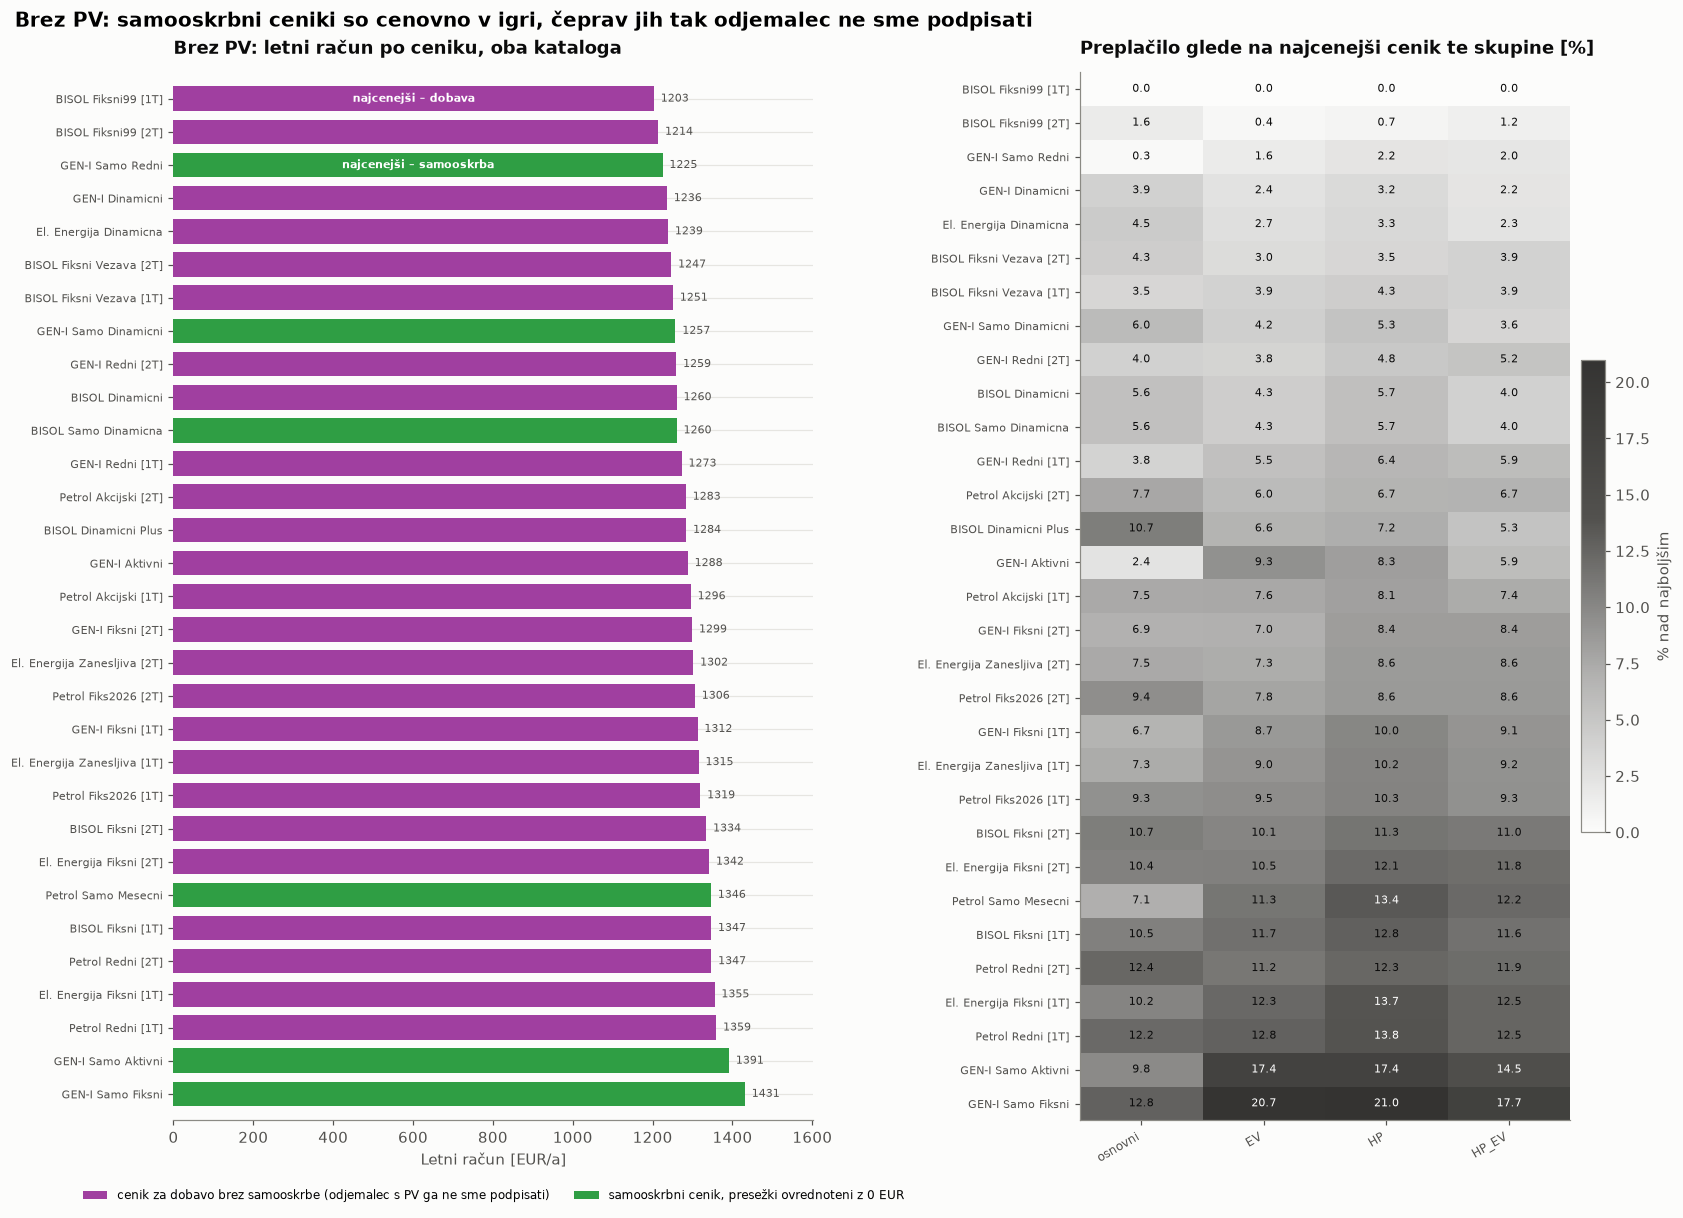

Dataset,Fluvius,Fluvius_EV,Fluvius_HP,Fluvius_HP_EV
Option,,,,
BISOL_FIKSNI99@1T,0.00,0.00,0.00,0.00
BISOL_FIKSNI99@2T,1.59,0.43,0.68,1.15
GENI_SAMO_REDNI,0.26,1.62,2.18,1.98
GENI_DINAMICNI,3.95,2.39,3.16,2.18
ELEN_DINAMICNA,4.55,2.66,3.34,2.34
BISOL_FIKSNI_VEZAVA@2T,4.26,2.95,3.51,3.90
BISOL_FIKSNI_VEZAVA@1T,3.51,3.89,4.27,3.87
GENI_SAMO_DINAMICNI,6.04,4.16,5.25,3.59
GENI_REDNI@2T,3.96,3.77,4.83,5.18


In [17]:
### Both catalogues on one axis: the households with no roof
# Hue is spent on the catalogue rather than on magnitude, because every row here
# is under the same zeroed export regime and the regime channel is free.
def catalogue_bill_panel(ax, summary, title, xlabel="Letni račun [EUR/a]"):
    """Ranked annual bill, one bar per option, hue = which catalogue sells it."""
    ypos = np.arange(len(summary))[::-1]
    ax.barh(ypos, summary["Cost_EUR"], height=0.74,
            color=[CATALOGUE_COLOR[c] for c in summary["Catalogue"]])
    ax.set_yticks(ypos, [short_list_name(o) for o in summary.index], fontsize=7.5)
    bar_labels(ax, ypos, summary["Cost_EUR"].to_numpy(), fontsize=7.5)
    # The cheapest row of each catalogue is named inside its own bar.
    for catalogue in ("dobava", "samooskrba"):
        opt = cheapest_of(summary, catalogue)
        ax.text(summary.loc[opt, "Cost_EUR"] * 0.5,
                ypos[list(summary.index).index(opt)],
                f"najcenejši – {CATALOGUE_SHORT[catalogue]}", va="center",
                ha="center", fontsize=7.5, color="#ffffff", fontweight="semibold")
    ax.set_xlim(0, summary["Cost_EUR"].max() * 1.12)
    ax.set_ylim(-0.8, len(summary) - 0.2)
    finish(ax, title=title, xlabel=xlabel)
    ax.grid(axis="x")
    ax.spines["left"].set_visible(False)
    key_below(ax, [Patch(facecolor=CATALOGUE_COLOR[c]) for c in CATALOGUE_ORDER],
              [CATALOGUE_LABEL[c] for c in CATALOGUE_ORDER], ncol=1)
    return ypos


def catalogue_figure(name, bill_title, heat_title, export):
    """The chapter's two figures for one household set.

    First: every option ranked by its own bill. Second: the same rows against the
    cheapest option for each household TYPE -- the ranking is a mean and can hide
    a list that suits one kind of household and no other.

    They are two figures rather than two panels of one: at 31 price lists a row
    shared between them is unreadable at half of \\textwidth.

    The heatmap ramp is NEUTRAL rather than either catalogue's hue: its rows come
    from both shelves, and giving the magnitude one of the two categorical hues
    would read as a claim about which shelf the cell belongs to.
    """
    summary, rel = cat_summary[name], by_group_cat_rel[name]

    fig, ax = plt.subplots(figsize=pf.figsize(ratio=rows_ratio(len(summary),
                                                               per_row=0.30)))
    catalogue_bill_panel(ax, summary, bill_title)
    pf.show(fig, f"{export}_bill_ranking")

    fig, ax = plt.subplots(figsize=pf.figsize(ratio=rows_ratio(len(rel),
                                                               per_row=0.28)))
    overpay_heatmap(ax, rel, INK_2, heat_title, fig=fig,
                    cell_fontsize=6.5 if rel.shape[1] > 5 else 7.0,
                    label_fontsize=7.5)
    pf.show(fig, f"{export}_overpay_by_group")
    return rel


rel_no_pv = catalogue_figure(
    "no PV",
    "Brez PV: samooskrbni ceniki so cenovno v igri, čeprav jih tak odjemalec ne sme podpisati",
    "Brez PV, oba kataloga: preplačilo glede na najcenejši cenik te skupine [%]",
    "catalogue_no_pv")

rel_no_pv.round(2)

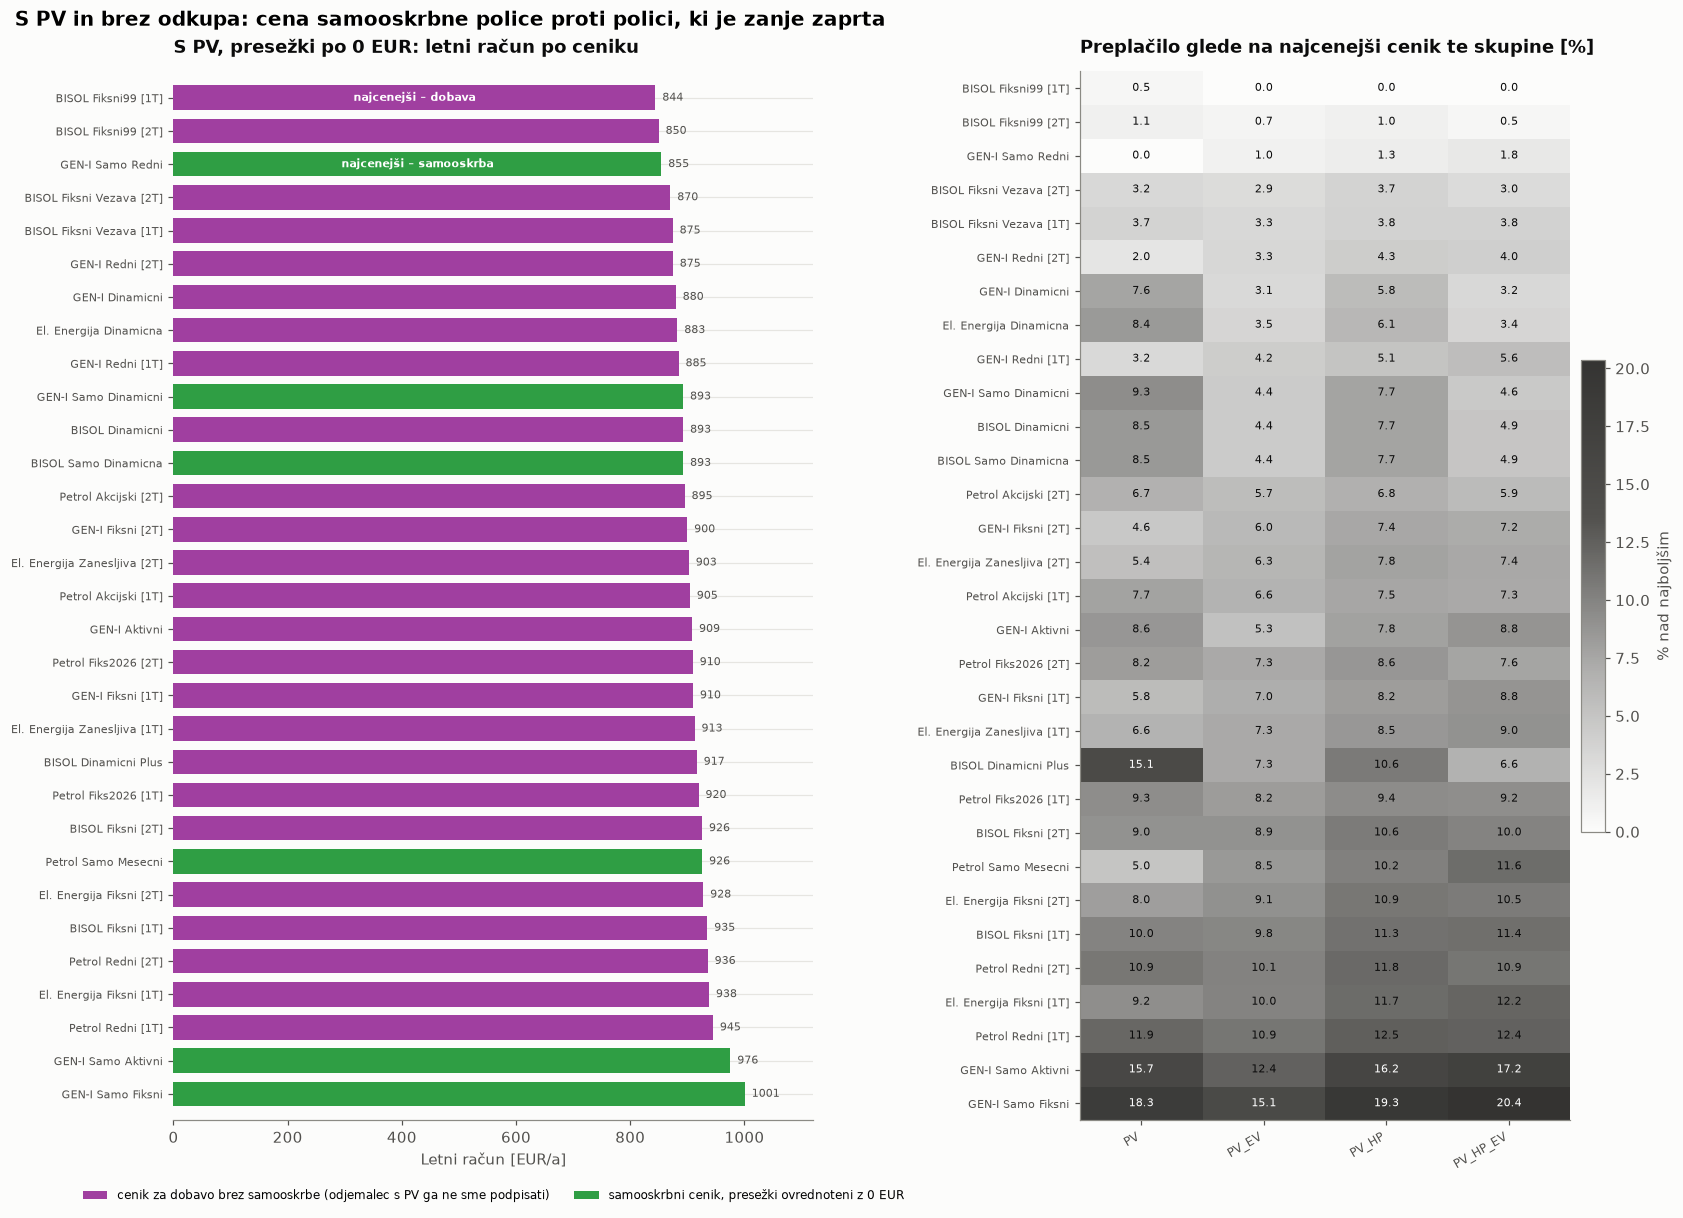

Dataset,Fluvius_PV,Fluvius_PV_EV,Fluvius_PV_HP,Fluvius_PV_HP_EV
Option,,,,
BISOL_FIKSNI99@1T,0.55,0.00,0.00,0.00
BISOL_FIKSNI99@2T,1.08,0.71,1.04,0.49
GENI_SAMO_REDNI,0.00,0.98,1.30,1.79
BISOL_FIKSNI_VEZAVA@2T,3.19,2.94,3.69,2.97
BISOL_FIKSNI_VEZAVA@1T,3.70,3.26,3.76,3.81
GENI_REDNI@2T,2.01,3.29,4.29,3.99
GENI_DINAMICNI,7.63,3.13,5.79,3.22
ELEN_DINAMICNA,8.41,3.47,6.13,3.42
GENI_REDNI@1T,3.16,4.24,5.06,5.60


In [18]:
### The same 32 options on the households that actually have a roof
# The half that is a real decision: these households are confined to the green
# rows by `dovoljuje_pv`, and the purple rows are what they are kept from.
rel_pv = catalogue_figure(
    "with PV",
    "S PV in brez odkupa: cena samooskrbne police proti polici, ki je zanje zaprta",
    "S PV, presežki po 0 EUR: preplačilo glede na najcenejši cenik te skupine [%]",
    "catalogue_with_pv")

rel_pv.round(2)

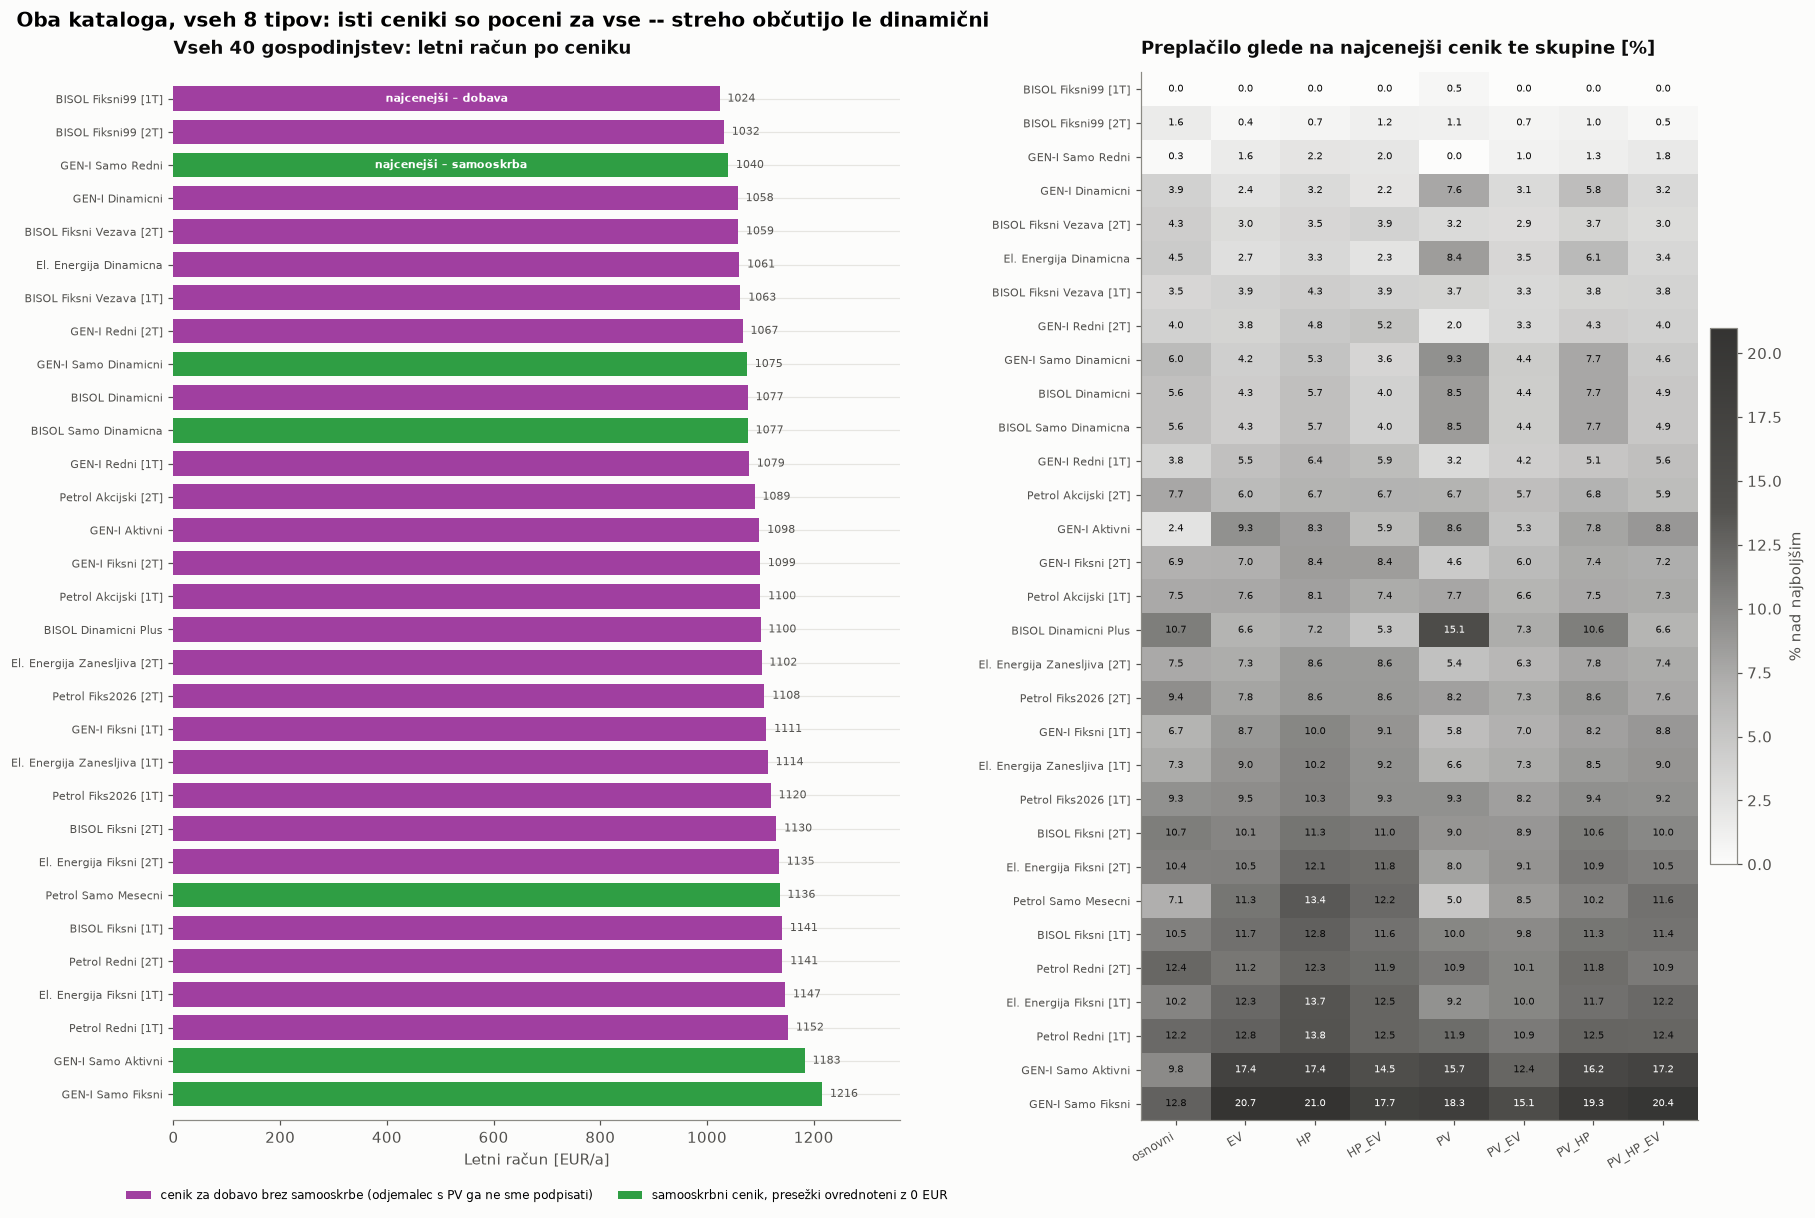

Dataset,Fluvius,Fluvius_EV,Fluvius_HP,Fluvius_HP_EV,Fluvius_PV,Fluvius_PV_EV,Fluvius_PV_HP,Fluvius_PV_HP_EV
Option,,,,,,,,
BISOL_FIKSNI99@1T,0.0,0.0,0.0,0.0,0.5,0.0,0.0,0.0
BISOL_FIKSNI99@2T,1.6,0.4,0.7,1.2,1.1,0.7,1.0,0.5
GENI_SAMO_REDNI,0.3,1.6,2.2,2.0,0.0,1.0,1.3,1.8
GENI_DINAMICNI,3.9,2.4,3.2,2.2,7.6,3.1,5.8,3.2
BISOL_FIKSNI_VEZAVA@2T,4.3,3.0,3.5,3.9,3.2,2.9,3.7,3.0
ELEN_DINAMICNA,4.5,2.7,3.3,2.3,8.4,3.5,6.1,3.4
BISOL_FIKSNI_VEZAVA@1T,3.5,3.9,4.3,3.9,3.7,3.3,3.8,3.8
GENI_REDNI@2T,4.0,3.8,4.8,5.2,2.0,3.3,4.3,4.0
GENI_SAMO_DINAMICNI,6.0,4.2,5.3,3.6,9.3,4.4,7.7,4.6


In [19]:
### All 40 households at once, both catalogues, all 8 household types
# Pooling is legitimate because with the credit zeroed the two halves were billed
# on identical terms (check 2 above). It buys the 8-column heatmap, the only
# panel that can show whether a roof changes the answer rather than the bill.
#
# It costs the ranking column, which is a mean over households whose bills differ
# by 400 EUR/a, so it ranks price lists rather than describing a household. Every
# delta beside it is measured per household first.
rel_all = catalogue_figure(
    "all",
    "Oba kataloga, vseh 8 tipov: isti ceniki so poceni za vse -- streho občutijo le dinamični",
    "Vseh 40 gospodinjstev: preplačilo glede na najcenejši cenik te skupine [%]",
    "catalogue_all")

rel_all.round(1)

findfont: Failed to find font weight semibold, now using 700.


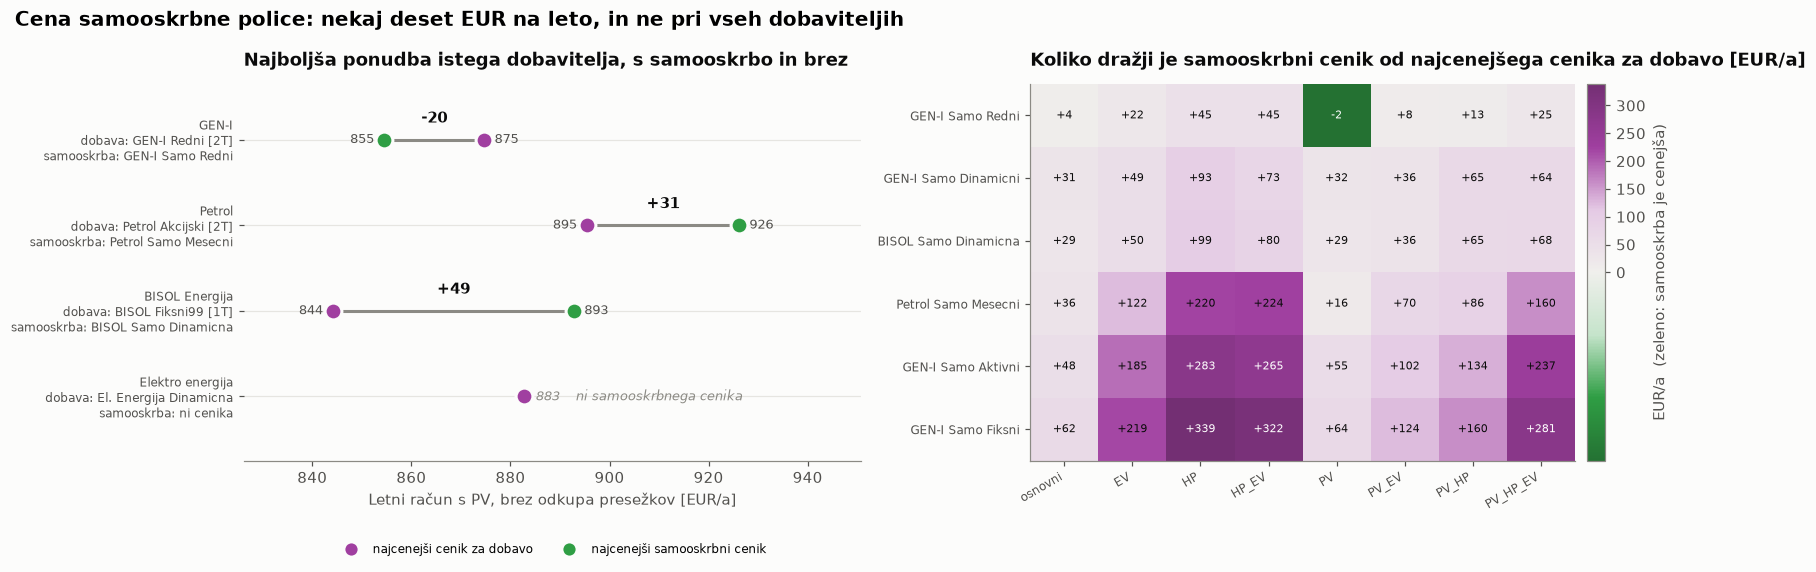

,najcenejša dobava [EUR/a],najcenejša samooskrba [EUR/a],razlika [EUR/a],cenikov za dobavo,samooskrbnih cenikov
Supplier,,,,,
GEN-I,874.74,854.53,-20.21,6,4
Petrol,895.46,926.19,30.72,6,1
BISOL Energija,844.20,892.86,48.67,8,1
Elektro energija,882.69,NaN,NaN,5,0


In [20]:
### What the samooskrba shelf costs: against the whole supply shelf, and per supplier
# A difference between two contracts for the same household, so it is computed
# per household and then averaged, never as a difference of two group means.
cat_all = df_cat_all.assign(Catalogue=[catalogue_of(o) for o in df_cat_all["Option"]])
best_supply = (cat_all[cat_all["Catalogue"] == "dobava"]
               .groupby(["Dataset", "Household"])["Cost_EUR"].min())
samo = cat_all[cat_all["Catalogue"] == "samooskrba"].copy()
samo["Premium_EUR"] = samo["Cost_EUR"] - samo.set_index(
    ["Dataset", "Household"]).index.map(best_supply)
premium_by_group = (samo.pivot_table(index="Option", columns="Dataset",
                                     values="Premium_EUR")
                    .reindex([o for o in cat_summary["all"].index
                              if catalogue_of(o) == "samooskrba"]))

# Per supplier, on the households held to this choice: the cheapest thing it will
# sell a roof against the cheapest thing it would sell the same house without
# one. A comparison of shelves, best offer against best offer.
pv_summary_cat = cat_summary["with PV"]
supplier_rows = []
for supplier in sorted(pv_summary_cat["Supplier"].unique()):
    shelf = pv_summary_cat[pv_summary_cat["Supplier"] == supplier]
    dobava = shelf[shelf["Catalogue"] == "dobava"]
    samoo = shelf[shelf["Catalogue"] == "samooskrba"]
    supplier_rows.append({
        "Supplier": supplier,
        "Dobava_Option": dobava.index[0] if len(dobava) else None,
        "Dobava_EUR": float(dobava["Cost_EUR"].iloc[0]) if len(dobava) else np.nan,
        "Samooskrba_Option": samoo.index[0] if len(samoo) else None,
        "Samooskrba_EUR": float(samoo["Cost_EUR"].iloc[0]) if len(samoo) else np.nan,
        "Lists_Dobava": len(dobava), "Lists_Samooskrba": len(samoo),
    })
supplier_premium = pd.DataFrame(supplier_rows).set_index("Supplier")
supplier_premium["Premium_EUR"] = (supplier_premium["Samooskrba_EUR"]
                                   - supplier_premium["Dobava_EUR"])
supplier_premium = supplier_premium.sort_values("Premium_EUR", na_position="last")

# --- one row per supplier, one dot per shelf ---------------------------------
# A dumbbell, as in chapter 4: the finding is the distance between two contracts
# for the same household.
fig, ax = plt.subplots(figsize=pf.figsize(
    ratio=rows_ratio(len(supplier_premium), per_row=0.66, floor=3.6)))
ypos = np.arange(len(supplier_premium))[::-1]
bills = supplier_premium[["Dobava_EUR", "Samooskrba_EUR"]].to_numpy()
lo_x, hi_x = float(np.nanmin(bills)), float(np.nanmax(bills))
span = hi_x - lo_x
for y, (supplier, row) in zip(ypos, supplier_premium.iterrows()):
    dob, sam = row["Dobava_EUR"], row["Samooskrba_EUR"]
    ax.plot(dob, y, marker="o", ms=11, color=CATALOGUE_COLOR["dobava"],
            mec=SURFACE, mew=2.0, zorder=3)
    if np.isnan(sam):
        # A supplier with no samooskrba list is a closed door, not a zero
        # premium: one dot, said in words rather than drawn as a gap.
        ax.text(dob + span * 0.03, y, f"{dob:.0f}    ni samooskrbnega cenika",
                va="center", ha="left", fontsize=8.5, color=MUTED, style="italic")
        continue
    ax.plot([dob, sam], [y, y], color=MUTED, lw=2.0, zorder=1,
            solid_capstyle="round")
    ax.plot(sam, y, marker="o", ms=11, color=CATALOGUE_COLOR["samooskrba"],
            mec=SURFACE, mew=2.0, zorder=3)
    left, right = min(dob, sam), max(dob, sam)
    ax.text(left - span * 0.025, y, f"{left:.0f}", va="center", ha="right",
            fontsize=8.5, color=INK_2)
    ax.text(right + span * 0.025, y, f"{right:.0f}", va="center", ha="left",
            fontsize=8.5, color=INK_2)
    ax.text((dob + sam) / 2, y + 0.16, f"{row['Premium_EUR']:+.0f}",
            va="bottom", ha="center", fontsize=9.5, color=INK,
            fontweight="semibold")
# Which two lists a row compares belongs in the row label: at 20 EUR/a apart the
# two names would overlap under the dots.
ax.set_yticks(ypos, [
    f"{s}\ndobava: {short_list_name(r['Dobava_Option'])}\n"
    + (f"samooskrba: {short_list_name(r['Samooskrba_Option'])}"
       if pd.notna(r["Samooskrba_Option"]) else "samooskrba: ni cenika")
    for s, r in supplier_premium.iterrows()], fontsize=8)
ax.set_xlim(lo_x - span * 0.22, hi_x + span * 0.30)
ax.set_ylim(-0.75, len(supplier_premium) - 0.35)
finish(ax, title="Najboljša ponudba istega dobavitelja, s samooskrbo in brez",
       xlabel="Letni račun s PV, brez odkupa presežkov [EUR/a]")
ax.grid(axis="x")
ax.spines["left"].set_visible(False)
key_below(ax,
          [plt.Line2D([], [], marker="o", ls="", ms=10, mec=SURFACE, mew=2.0,
                      color=CATALOGUE_COLOR[c]) for c in CATALOGUE_ORDER],
          ["najcenejši cenik za dobavo", "najcenejši samooskrbni cenik"], ncol=2)
pf.show(fig, "catalogue_premium_by_supplier")

# --- the premium itself, per option and per household type -------------------
# A signed quantity with a meaningful zero, so the one diverging scale here:
# purple where the supply shelf wins, green where this samooskrba list beats
# everything on it, neutral at the tie. `TwoSlopeNorm` keeps the zero on the
# neutral colour, the negative side being too small for a symmetric scale.
fig, ax = plt.subplots(figsize=pf.figsize(
    ratio=rows_ratio(len(premium_by_group), per_row=0.30)))
values = premium_by_group.to_numpy()
diverging = LinearSegmentedColormap.from_list("catalogue_div", [
    pf.mix(CATALOGUE_COLOR["samooskrba"], "#0b0b0b", 0.30),
    CATALOGUE_COLOR["samooskrba"],
    pf.mix(CATALOGUE_COLOR["samooskrba"], "#ffffff", 0.72),
    "#f0efec",
    pf.mix(CATALOGUE_COLOR["dobava"], "#ffffff", 0.72),
    CATALOGUE_COLOR["dobava"],
    pf.mix(CATALOGUE_COLOR["dobava"], "#0b0b0b", 0.30)])
norm = TwoSlopeNorm(vmin=float(np.nanmin(values)), vcenter=0.0,
                    vmax=float(np.nanmax(values)))
im = ax.imshow(values, cmap=diverging, norm=norm, aspect="auto")
ax.set_xticks(range(premium_by_group.shape[1]),
              [group_label(c) for c in premium_by_group.columns],
              rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(premium_by_group.shape[0]),
              [short_list_name(o) for o in premium_by_group.index], fontsize=8)
ax.grid(False)
for r in range(values.shape[0]):
    for c in range(values.shape[1]):
        strong = norm(values[r, c]) > 0.86 or norm(values[r, c]) < 0.14
        ax.text(c, r, f"{values[r, c]:+.0f}", ha="center", va="center",
                fontsize=7.5, color="#ffffff" if strong else INK)
finish(ax, title="Koliko dražji je samooskrbni cenik od najcenejšega cenika za dobavo "
                 "[EUR/a]")
fig.colorbar(im, ax=ax, fraction=0.045, pad=0.02,
             label="EUR/a  (zeleno: samooskrba je cenejša)")
pf.show(fig, "catalogue_premium_by_group")

supplier_premium[["Dobava_EUR", "Samooskrba_EUR", "Premium_EUR",
                  "Lists_Dobava", "Lists_Samooskrba"]].rename(columns={
    "Dobava_EUR": "najcenejša dobava [EUR/a]",
    "Samooskrba_EUR": "najcenejša samooskrba [EUR/a]",
    "Premium_EUR": "razlika [EUR/a]",
    "Lists_Dobava": "cenikov za dobavo",
    "Lists_Samooskrba": "samooskrbnih cenikov",
}).round(2)

In [21]:
### Read-out: what the samooskrba shelf costs, and what it costs to pick wrongly on it
# Both quantities are paired: the two shelves are compared on the same house and
# then averaged. `Vs_Supply` is built against the cheapest supply option for that
# household rather than against the cheapest on average.
lock_in, vs_supply = {}, {}
for name, frame in SETS.items():
    tagged = frame.assign(Catalogue=[catalogue_of(o) for o in frame["Option"]])
    shelves = tagged.pivot_table(index=["Dataset", "Household"], columns="Catalogue",
                                 values="Cost_EUR", aggfunc="min")
    lock_in[name] = shelves["samooskrba"] - shelves["dobava"]
    samo_rows = tagged[tagged["Catalogue"] == "samooskrba"]
    vs_supply[name] = (samo_rows.assign(
        Vs_Supply=samo_rows["Cost_EUR"] - samo_rows.set_index(
            ["Dataset", "Household"]).index.map(shelves["dobava"]))
        .groupby("Option")["Vs_Supply"].mean())

pv_lock = lock_in["with PV"]
pv_sum = cat_summary["with PV"]
pv_best_samo = cheapest_of(pv_sum, "samooskrba")
pv_worst_samo = pv_sum[pv_sum["Catalogue"] == "samooskrba"].index[-1]
samo_spread = (pv_sum.loc[pv_worst_samo, "Cost_EUR"]
               - pv_sum.loc[pv_best_samo, "Cost_EUR"])
order = list(pv_sum.index)

lines = [f"{'samooskrbni cenik':26s}{'rank':>7s}{'račun':>9s}"
         f"{'vs najboljši [EUR/a]':>22s}{'vs najcenejša dobava':>22s}"]
for opt in [o for o in order if pv_sum.loc[o, "Catalogue"] == "samooskrba"]:
    lines.append(f"{short_list_name(opt):26s}{order.index(opt) + 1:>4d}/32"
                 f"{pv_sum.loc[opt, 'Cost_EUR']:>9.0f}"
                 f"{pv_sum.loc[opt, 'Delta_EUR']:>22.0f}"
                 f"{vs_supply['with PV'][opt]:>+22.0f}")

# Which supply lists a samooskrba list is a rate-card copy of, detected from the
# bills: a reprinted rate card lands on the same euro for every household.
identical = []
for samo_opt in [o for o in order if pv_sum.loc[o, "Catalogue"] == "samooskrba"]:
    for dob_opt in [o for o in order if pv_sum.loc[o, "Catalogue"] == "dobava"]:
        drift = (df_cat_pv[df_cat_pv["Option"] == samo_opt]
                 .set_index(["Dataset", "Household"])["Cost_EUR"]
                 - df_cat_pv[df_cat_pv["Option"] == dob_opt]
                 .set_index(["Dataset", "Household"])["Cost_EUR"])
        if float(drift.abs().max()) == 0.0:
            identical.append((samo_opt, dob_opt))

geni = supplier_premium.loc["GEN-I"]
geni_dyn, geni_samo_dyn = (hc.option_paket("GENI_DINAMICNI"),
                           hc.option_paket("GENI_SAMO_DINAMICNI"))
dyn_premium = (pv_sum.loc["GENI_SAMO_DINAMICNI", "Cost_EUR"]
               - pv_sum.loc["GENI_DINAMICNI", "Cost_EUR"])
# The two GEN-I aktivni samooskrba lists against the supply aktivni list, block
# by block.
_blocks = ("soncna_ns", "soncna_vs", "osnovna", "konicna")
dearer_in_every_block = [
    o for o in ("GENI_SAMO_AKTIVNI", "GENI_SAMO_FIKSNI")
    if all(getattr(hc.option_paket(o), b) > getattr(hc.option_paket("GENI_AKTIVNI"), b)
           for b in _blocks)]
no_samo = list(supplier_premium.index[supplier_premium["Samooskrba_EUR"].isna()])

rank_no_pv, rank_pv = list(cat_summary["no PV"].index), list(cat_summary["with PV"].index)
shift = pd.DataFrame({
    "structure": [hc.option_paket(o).tip_cene.value for o in rank_no_pv],
    "shift": [rank_pv.index(o) - rank_no_pv.index(o) for o in rank_no_pv],
}).groupby("structure")["shift"].agg(["mean", "size"])

lines += [
    "",
    f"THE PRICE OF THE SHELF. Being confined to the samooskrba catalogue costs a PV "
    f"household {pv_lock.mean():.0f} EUR/a on",
    f"average -- {short_list_name(pv_best_samo)} at "
    f"{pv_sum.loc[pv_best_samo, 'Cost_EUR']:.0f} EUR/a against "
    f"{short_list_name(pv_sum.index[0])} at {pv_sum['Cost_EUR'].iloc[0]:.0f} EUR/a, "
    f"the cheapest of all 32. That is",
    f"{100 * pv_lock.mean() / pv_sum['Cost_EUR'].iloc[0]:.1f} % of the bill, and it is "
    f"not a uniform tax:",
    f"   {(pv_lock < 0).sum()} of {len(pv_lock)} PV households pay LESS on the samooskrba "
    f"shelf than on anything the supply shelf would sell them,",
    f"   median {pv_lock.median():.0f} EUR/a, best case {pv_lock.min():+.0f} EUR/a "
    f"({pv_lock.idxmin()[0]} household {pv_lock.idxmin()[1]}), worst case "
    f"{pv_lock.max():+.0f} EUR/a ({pv_lock.idxmax()[0]} household {pv_lock.idxmax()[1]}),",
    f"   and {pv_lock.sum():.0f} EUR/a for the {len(pv_lock)} of them together -- next to "
    f"{df_cat_pv.groupby(['Dataset', 'Household'])['Export_kWh'].first().sum():.0f} kWh/a "
    f"of surplus they are giving away.",
    "",
    "It is a difference between two per-kWh rates paid on the residual import, so it "
    "grows with what the roof does",
    "NOT cover -- smallest on the plain PV households, largest where a heat pump and an "
    "EV are behind the same roof:",
    *[f"   {group_label(g):10s} {lock_in['with PV'].xs(g).mean():6.1f} EUR/a"
      f"      {group_label(ng):8s} {lock_in['no PV'].xs(ng).mean():6.1f} EUR/a"
      for g, ng in zip(hc.PV_GROUPS, hc.NO_PV_GROUPS)],
    "   (right-hand column: the same household TYPE with no roof -- a different sample "
    "of houses, not the same ones,",
    "   and a shelf it may not buy from either way. It is there to show the effect is "
    "the demand, not the roof.)",
    "",
    f"THE PRICE OF CHOOSING BADLY ON IT. The same household moving from "
    f"{short_list_name(pv_best_samo)} to",
    f"{short_list_name(pv_worst_samo)} -- both samooskrba lists, both signable, same "
    f"roof, same year -- pays {samo_spread:.0f} EUR/a more.",
    f"That is {samo_spread / pv_lock.mean():.0f}x the cost of the shelf itself. Which "
    f"catalogue a household is confined to is a rounding error",
    "next to the choice it makes inside that catalogue -- the same finding chapters 1-3 "
    "reached from the other side.",
    "",
    f"WHY THE SHELF COSTS ANYTHING AT ALL. Not a samooskrba surcharge: "
    f"{len(identical)} of the {len(prosumer_options)} options are the same rate",
    "card as a supply list from the same supplier, to the cent, on every household --",
    *[f"   {short_list_name(s):26s} == {short_list_name(d)}" for s, d in identical],
    f"   {short_list_name(pv_best_samo):26s} is cheaper than EVERY GEN-I supply option "
    f"({pv_sum.loc[pv_best_samo, 'Cost_EUR']:.0f} against "
    f"{geni['Dobava_EUR']:.0f} EUR/a on {short_list_name(geni['Dobava_Option'])}),",
    f"   {'':26s} on an ET rate of "
    f"{hc.option_paket(pv_best_samo).et:.5f} against "
    f"{hc.option_paket('GENI_REDNI@1T').et:.5f} on the plain Redni.",
    f"   {short_list_name('GENI_SAMO_DINAMICNI'):26s} costs {dyn_premium:+.0f} EUR/a "
    f"against {short_list_name('GENI_DINAMICNI')} on an identical spread",
    f"   {'':26s} (SIPX + {geni_samo_dyn.pribitek_odjem:.5f} on both), because the "
    f"supply list caps SIPX at {geni_dyn.cap_sipx:.2f} EUR/kWh",
    f"   {'':26s} and the samooskrba one publishes no cap at all. The premium is "
    f"the cap, not the energy.",
    f"   {', '.join(short_list_name(o) for o in dearer_in_every_block):26s} are the "
    f"two dearest options of all 32, and all four of their tariff",
    f"   {'':26s} blocks are priced above the supply aktivni list's.",
    "",
    f"AND ONE SUPPLIER IS SIMPLY CLOSED. {', '.join(no_samo)} publishes "
    f"{int(supplier_premium.loc[no_samo[0], 'Lists_Dobava'])} supply options and no "
    f"samooskrba list at all,",
    "so a household that puts up a roof stops being able to buy from them. That is not a "
    "premium, and it is",
    "invisible in any table that ranks only the lists a household may sign.",
    "",
    "DOES THE ROOF CHANGE THE ANSWER? Barely, and where it does the reason is the tariff "
    "structure, not the catalogue:",
    *[f"   {s:10s} {row['mean']:+5.1f} places on average with a roof "
      f"({int(row['size'])} options)" for s, row in shift.iterrows()],
    "The dynamic lists lose ground on a PV household because what is left to import after "
    "the roof is the winter and",
    "the evening -- exactly the hours SIPX is expensive -- while a flat list charges the "
    "same rate whenever the import falls.",
    "",
    f"The excess-power charge is {pv_sum['Excess_Power_EUR'].mean():.2f} EUR/a and "
    f"identical on all 32 options in both catalogues,",
    "because no contract of either kind can move a network charge. It is still the only "
    "line a battery could.",
]
print("\n".join(lines))

samooskrbni cenik            rank    račun  vs najboljši [EUR/a]  vs najcenejša dobava
GEN-I Samo Redni             3/32      855                    12                   +11
GEN-I Samo Dinamicni        10/32      893                    50                   +49
BISOL Samo Dinamicna        12/32      893                    50                   +49
Petrol Samo Mesecni         24/32      926                    83                   +83
GEN-I Samo Aktivni          30/32      976                   133                  +132
GEN-I Samo Fiksni           31/32     1001                   158                  +157

THE PRICE OF THE SHELF. Being confined to the samooskrba catalogue costs a PV household 10 EUR/a on
average -- GEN-I Samo Redni at 855 EUR/a against BISOL Fiksni99 [1T] at 844 EUR/a, the cheapest of all 32. That is
1.2 % of the bill, and it is not a uniform tax:
   4 of 20 PV households pay LESS on the samooskrba shelf than on anything the supply shelf would sell them,
   median 11 EUR/a

### Caveats

* **No battery, anywhere.** Every answer here is a contract answer; nothing below says what a
  battery is worth. It says what the contract is worth, which is the number a battery result has
  to beat.
* **The excess-power charge is identical on every list, in every chapter**, because it is a
  network charge. It appears in all totals so each is a real bill, but it can never be a reason
  to prefer a contract.
* **The profiles are already netted, so self-consumption is invisible.** Every euro in chapters
  2–4 is about the residual import and the residual surplus. Chapter 3 removes the value of the
  surplus, not of the roof.
* **Interval-level netting is physical, not contractual.** What the contract decides is only what
  a surplus is worth. Routing a no-buyback household through `si_dobava` would credit its exports
  at the full retail rate including network charges and VAT — unbounded arbitrage.
* **Chapter 5 prices two shelves neither household may fully shop from.** Each half has one
  counterfactual column: the rates of the shelf its household is barred from, applied to its own
  registers. With the credit zeroed the two schemes bill identical terms, so the counterfactual
  bill is a real bill on published rates and the only fiction is the signature.
* **A row is a contract and a meter.** Rows with no tag have no such choice to offer. No
  *samooskrba* list carries a tag: self-consumption is billed on the single ET rate by
  construction. The `et` field on an *aktivni* list is not a variant but the substitute rate for
  intervals with no 15-minute metering.
* **The variant is priced by the pricing library, not re-derived here.** The 1T reading is
  `dataclasses.replace(paket, vt=0, mt=0)`, passed to `calculate_interval_price` as an object
  rather than registered in `PAKETI`.
* **`PER_GROUP` changes the sample, not the method.** Every comparison stamps its own
  `Per_Group` and refuses a cache written at another setting; a lower value costs precision in
  the per-household spreads, which are order statistics.
* **`Delta_pct` is measured per household, then averaged.** `Worst_Delta_pct` reports the single
  household an option treats worst.
* **The agreed power is a policy, not an optimum**, but it is identical for every household,
  list and chapter, so it cannot move a comparison.
* **NET metering is absent on purpose**, being closed to new consents and settled once a year.
* **One year, one price regime, 2026 rules**, with the SIPX series from 2024.